**Machine Learning**


Types
Supervised Learning
unsupervised Learning
semi supervised Learning
reinforcement Learning
self supervised Learning

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
cc = pd.read_csv('/content/Customer-Churn-Records.csv')

In [ ]:
cc.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [ ]:
cc.drop(['RowNumber','CustomerId','Surname','Complain','Satisfaction Score','Card Type','Point Earned'],axis=1,inplace=True)

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression

In [ ]:
le_gender = LabelEncoder()
cc['Gender']=le_gender.fit_transform(cc['Gender'])

In [ ]:
cc.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,0,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,0,41,1,83807.86,1,0,1,112542.58,0
2,502,France,0,42,8,159660.80,3,1,0,113931.57,1
3,699,France,0,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,0,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
#one hot encoding
cc_encoded = pd.get_dummies(cc,columns=['Geography'])

In [ ]:
cc_encoded.head(10)

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,True,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,False,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,True,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,True,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,False,False,True
5,645,1,44,8,113755.78,2,1,0,149756.71,1,False,False,True
6,822,1,50,7,0.00,2,1,1,10062.80,0,True,False,False
7,376,0,29,4,115046.74,4,1,0,119346.88,1,False,True,False
8,501,1,44,4,142051.07,2,0,1,74940.50,0,True,False,False
9,684,1,27,2,134603.88,1,1,1,71725.73,0,True,False,False


Nmaes of scalers that exist in sklearn
Why do we split our training data into training and test set

In [ ]:
#fit tells how to handle or encode data
#transform converts or transforms data

In [ ]:
X = cc_encoded.drop('Exited',axis=1)
y = cc_encoded['Exited']

In [ ]:
X

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,True,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,False,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,True,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,True,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,1,39,5,0.00,2,1,0,96270.64,True,False,False
9996,516,1,35,10,57369.61,1,1,1,101699.77,True,False,False
9997,709,0,36,7,0.00,1,0,1,42085.58,True,False,False
9998,772,1,42,3,75075.31,2,1,0,92888.52,False,True,False


In [ ]:
y

,Exited
0,1
1,0
2,1
3,0
4,0
...,...
9995,0
9996,0
9997,1
9998,1


In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
X_train

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
9254,686,1,32,6,0.00,2,1,1,179093.26,True,False,False
1561,632,1,42,4,119624.60,2,1,1,195978.86,False,True,False
1670,559,1,24,3,114739.92,1,1,0,85891.02,False,False,True
6087,561,0,27,9,135637.00,1,1,0,153080.40,True,False,False
6669,517,1,56,9,142147.32,1,0,0,39488.04,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
5734,768,1,54,8,69712.74,1,1,1,69381.05,True,False,False
5191,682,0,58,1,0.00,1,1,1,706.50,True,False,False
5390,735,0,38,1,0.00,3,0,0,92220.12,True,False,False
860,667,1,43,8,190227.46,1,1,0,97508.04,True,False,False


In [ ]:
y_train

,Exited
9254,0
1561,0
1670,1
6087,1
6669,1
...,...
5734,0
5191,0
5390,1
860,1


In [ ]:
from sklearn.preprocessing import MinMaxScaler

numerical_cols = ['CreditScore','Age','Tenure','Balance','NumOfProducts','EstimatedSalary']

scaler = MinMaxScaler()

X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

In [ ]:
X_train

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
9254,0.672,1,0.189189,0.6,0.000000,0.333333,1,1,0.895550,True,False,False
1561,0.564,1,0.324324,0.4,0.476786,0.333333,1,1,0.980029,False,True,False
1670,0.418,1,0.081081,0.3,0.457317,0.000000,1,0,0.429261,False,False,True
6087,0.422,0,0.121622,0.9,0.540606,0.000000,1,0,0.765408,True,False,False
6669,0.334,1,0.513514,0.9,0.566554,0.000000,0,0,0.197107,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0.836,1,0.486486,0.8,0.277853,0.000000,1,1,0.346662,True,False,False
5191,0.664,0,0.540541,0.1,0.000000,0.000000,1,1,0.003084,True,False,False
5390,0.770,0,0.270270,0.1,0.000000,0.666667,0,0,0.460925,True,False,False
860,0.634,1,0.337838,0.8,0.758186,0.000000,1,0,0.487381,True,False,False


In [ ]:
X_test

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
6252,0.492,1,0.189189,0.3,0.385452,0.333333,0,0,0.208616,False,True,False
4684,0.546,1,0.337838,0.1,0.000000,0.333333,1,1,0.731883,True,False,False
1731,0.502,0,0.351351,0.4,0.000000,0.333333,1,0,0.292531,False,False,True
4742,0.312,1,0.554054,0.8,0.474902,0.333333,1,1,0.853458,False,True,False
4521,0.420,0,0.121622,0.7,0.498194,0.000000,1,1,0.573241,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
6412,0.504,0,0.472973,0.5,0.391668,0.000000,0,1,0.224875,False,True,False
8285,0.518,1,0.094595,1.0,0.000000,0.000000,0,1,0.549353,True,False,False
7853,0.760,0,0.391892,0.7,0.000000,0.000000,1,0,0.166515,True,False,False
1095,0.684,1,0.148649,0.4,0.000000,0.000000,1,0,0.383558,True,False,False


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train,y_train)

LogisticRegression()

In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score,f1_score,precision_score,recall_score



In [ ]:
y_pred = model.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test,y_pred)

accuracy

0.8125

In [ ]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[1550,   57],
       [ 318,   75]])

In [ ]:
accuracy_score(y_train,model.predict(X_train))

0.81175

In [ ]:
df = pd.read_csv('/content/tested.csv')
df.head(20)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
5,897,0,3,"Svensson, Mr. Johan Cervin",male,14.0,0,0,7538,9.2250,NaN,S
6,898,1,3,"Connolly, Miss. Kate",female,30.0,0,0,330972,7.6292,NaN,Q
7,899,0,2,"Caldwell, Mr. Albert Francis",male,26.0,1,1,248738,29.0000,NaN,S
8,900,1,3,"Abrahim, Mrs. Joseph (Sophie Halaut Easu)",female,18.0,0,0,2657,7.2292,NaN,C
9,901,0,3,"Davies, Mr. John Samuel",male,21.0,2,0,A/4 48871,24.1500,NaN,S


In [ ]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,86
SibSp,0
Parch,0
Ticket,0
Fare,1


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop(['PassengerId','Name','Ticket','Cabin'],axis=1,inplace=True)

In [ ]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [ ]:
df.isna().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,1
Embarked,0


In [ ]:
df.dropna(subset=['Fare'],inplace=True)
df.isna().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


In [ ]:
df.head(10)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,34.5,0,0,7.8292,Q
1,1,3,female,47.0,1,0,7.0000,S
2,0,2,male,62.0,0,0,9.6875,Q
3,0,3,male,27.0,0,0,8.6625,S
4,1,3,female,22.0,1,1,12.2875,S
5,0,3,male,14.0,0,0,9.2250,S
6,1,3,female,30.0,0,0,7.6292,Q
7,0,2,male,26.0,1,1,29.0000,S
8,1,3,female,18.0,0,0,7.2292,C
9,0,3,male,21.0,2,0,24.1500,S


In [ ]:
le_gender= LabelEncoder()

df['Sex']=le_gender.fit_transform(df['Sex'])

In [ ]:
df_encoded = pd.get_dummies(df,columns=['Embarked'])

In [ ]:
df_encoded.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,34.5,0,0,7.8292,False,True,False
1,1,3,0,47.0,1,0,7.0000,False,False,True
2,0,2,1,62.0,0,0,9.6875,False,True,False
3,0,3,1,27.0,0,0,8.6625,False,False,True
4,1,3,0,22.0,1,1,12.2875,False,False,True


In [ ]:
X = df_encoded.drop('Survived',axis=1)
y = df['Survived']

In [ ]:
X

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,3,1,34.5,0,0,7.8292,False,True,False
1,3,0,47.0,1,0,7.0000,False,False,True
2,2,1,62.0,0,0,9.6875,False,True,False
3,3,1,27.0,0,0,8.6625,False,False,True
4,3,0,22.0,1,1,12.2875,False,False,True
...,...,...,...,...,...,...,...,...,...
413,3,1,27.0,0,0,8.0500,False,False,True
414,1,0,39.0,0,0,108.9000,True,False,False
415,3,1,38.5,0,0,7.2500,False,False,True
416,3,1,27.0,0,0,8.0500,False,False,True


In [ ]:
y

,Survived
0,0
1,1
2,0
3,0
4,1
...,...
413,0
414,1
415,0
416,0


In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
numerical_cols = ['Age','Fare']
scaler = MinMaxScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

In [ ]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
287,1,1,0.312806,1,0,0.312801,False,False,True
387,2,1,0.748910,0,0,0.049430,False,False,True
210,3,1,0.418528,0,0,0.085646,False,False,True
93,3,1,0.352451,0,0,0.030608,False,False,True
285,3,1,0.471389,0,0,0.027567,False,False,True
...,...,...,...,...,...,...,...,...,...
71,3,1,0.273160,0,0,0.030022,False,False,True
106,3,1,0.273160,0,0,0.029737,False,True,False
271,3,1,0.352451,0,0,0.029468,False,True,False
349,2,0,0.405313,0,0,0.079848,False,False,True


In [ ]:
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
153,3,0,0.471389,0,2,0.046324,False,False,True
398,3,1,0.286375,0,0,0.029563,False,False,True
412,3,0,0.365667,0,0,0.029563,False,False,True
94,1,1,0.326021,0,0,0.098859,True,False,False
70,3,0,0.312806,0,0,0.029468,False,True,False
...,...,...,...,...,...,...,...,...,...
24,1,0,0.629972,1,3,0.997624,True,False,False
17,3,1,0.273160,0,0,0.027471,True,False,False
66,3,0,0.233514,0,0,0.029959,False,True,False
169,3,0,0.286375,0,0,0.034078,False,False,True


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train,y_train)

LogisticRegression()

In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score,f1_score,precision_score,recall_score

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test,y_pred)

accuracy

1.0

In [ ]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[50,  0],
       [ 0, 34]])

In [ ]:
accuracy_score(y_train,model.predict(X_train))

1.0

In [ ]:
f1_score(y_test,y_pred)

1.0

In [ ]:
precision_score(y_test,y_pred)

1.0

In [ ]:
recall_score(y_test,y_pred)

1.0

In [ ]:
training_accuracy = accuracy_score(y_train,model.predict(X_train))
training_accuracy

1.0

In [ ]:
dc = pd.read_csv('/content/data.csv')
dc.head(20)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.26540,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.18600,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.24300,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.25750,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.16250,0.2364,0.07678,NaN
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.17410,0.3985,0.12440,NaN
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.19320,0.3063,0.08368,NaN
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510,NaN
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.20600,0.4378,0.10720,NaN
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.22100,0.4366,0.20750,NaN


In [ ]:
dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
dc.isna().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [ ]:
dc.drop(columns=['Unnamed: 32'],inplace=True)


In [ ]:
dc.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
dc.duplicated().sum()

np.int64(0)

In [ ]:
dc.drop(columns=['id'],inplace=True)


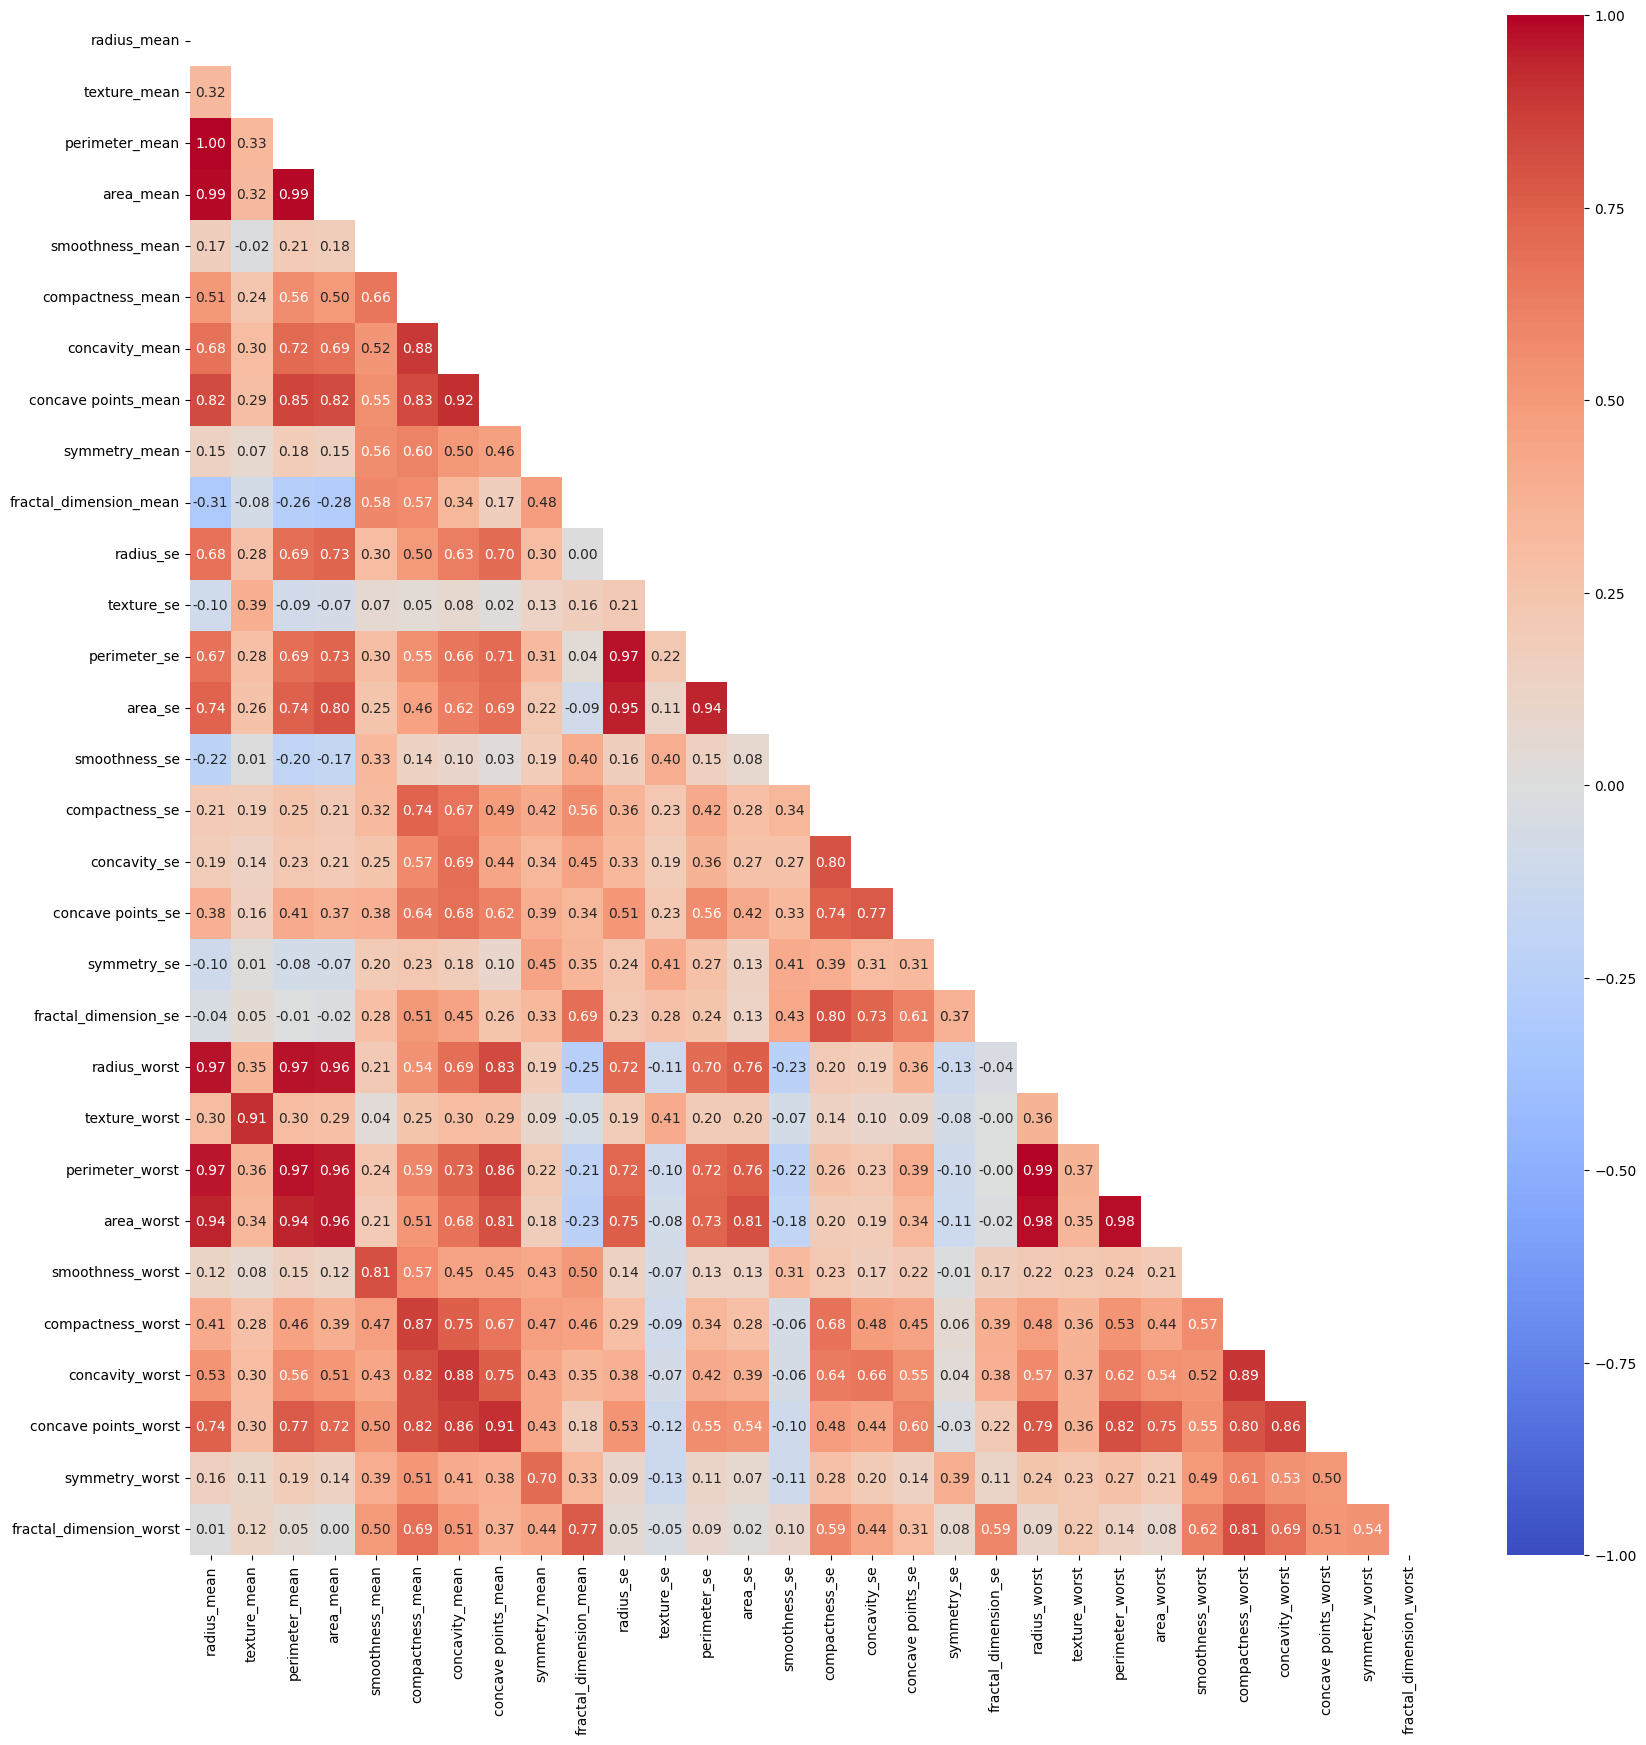

In [ ]:
corr = dc.corr(numeric_only=True)



plt.figure(figsize=(20,20))
sns.heatmap(corr,annot=True,fmt='.2f',mask=np.triu(corr),vmin=-1,vmax=1,center=0,cmap='coolwarm')
plt.show()

In [ ]:
worst_cols = [
    'radius_worst','texture_worst','perimeter_worst','area_worst','smoothness_worst','compactness_worst','concavity_worst','concave points_worst','symmetry_worst','fractal_dimension_worst']

In [ ]:
dc.drop(columns=worst_cols,inplace=True)

In [ ]:
perimeter_and_area_cols=['perimeter_mean','perimeter_se','area_mean','area_se']

In [ ]:
dc.drop(columns=perimeter_and_area_cols,inplace=True)
dc.head()

,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se
0,M,17.99,10.38,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193
1,M,20.57,17.77,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532
2,M,19.69,21.25,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571
3,M,11.42,20.38,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208
4,M,20.29,14.34,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115


In [ ]:
concavity_cols=['concavity_mean','concavity_se','concave points_mean','concave points_se']

In [ ]:
dc.drop(columns=concavity_cols,inplace=True)
dc.head()

,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,symmetry_se,fractal_dimension_se
0,M,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.03003,0.006193
1,M,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01389,0.003532
2,M,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.02250,0.004571
3,M,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05963,0.009208
4,M,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.01756,0.005115


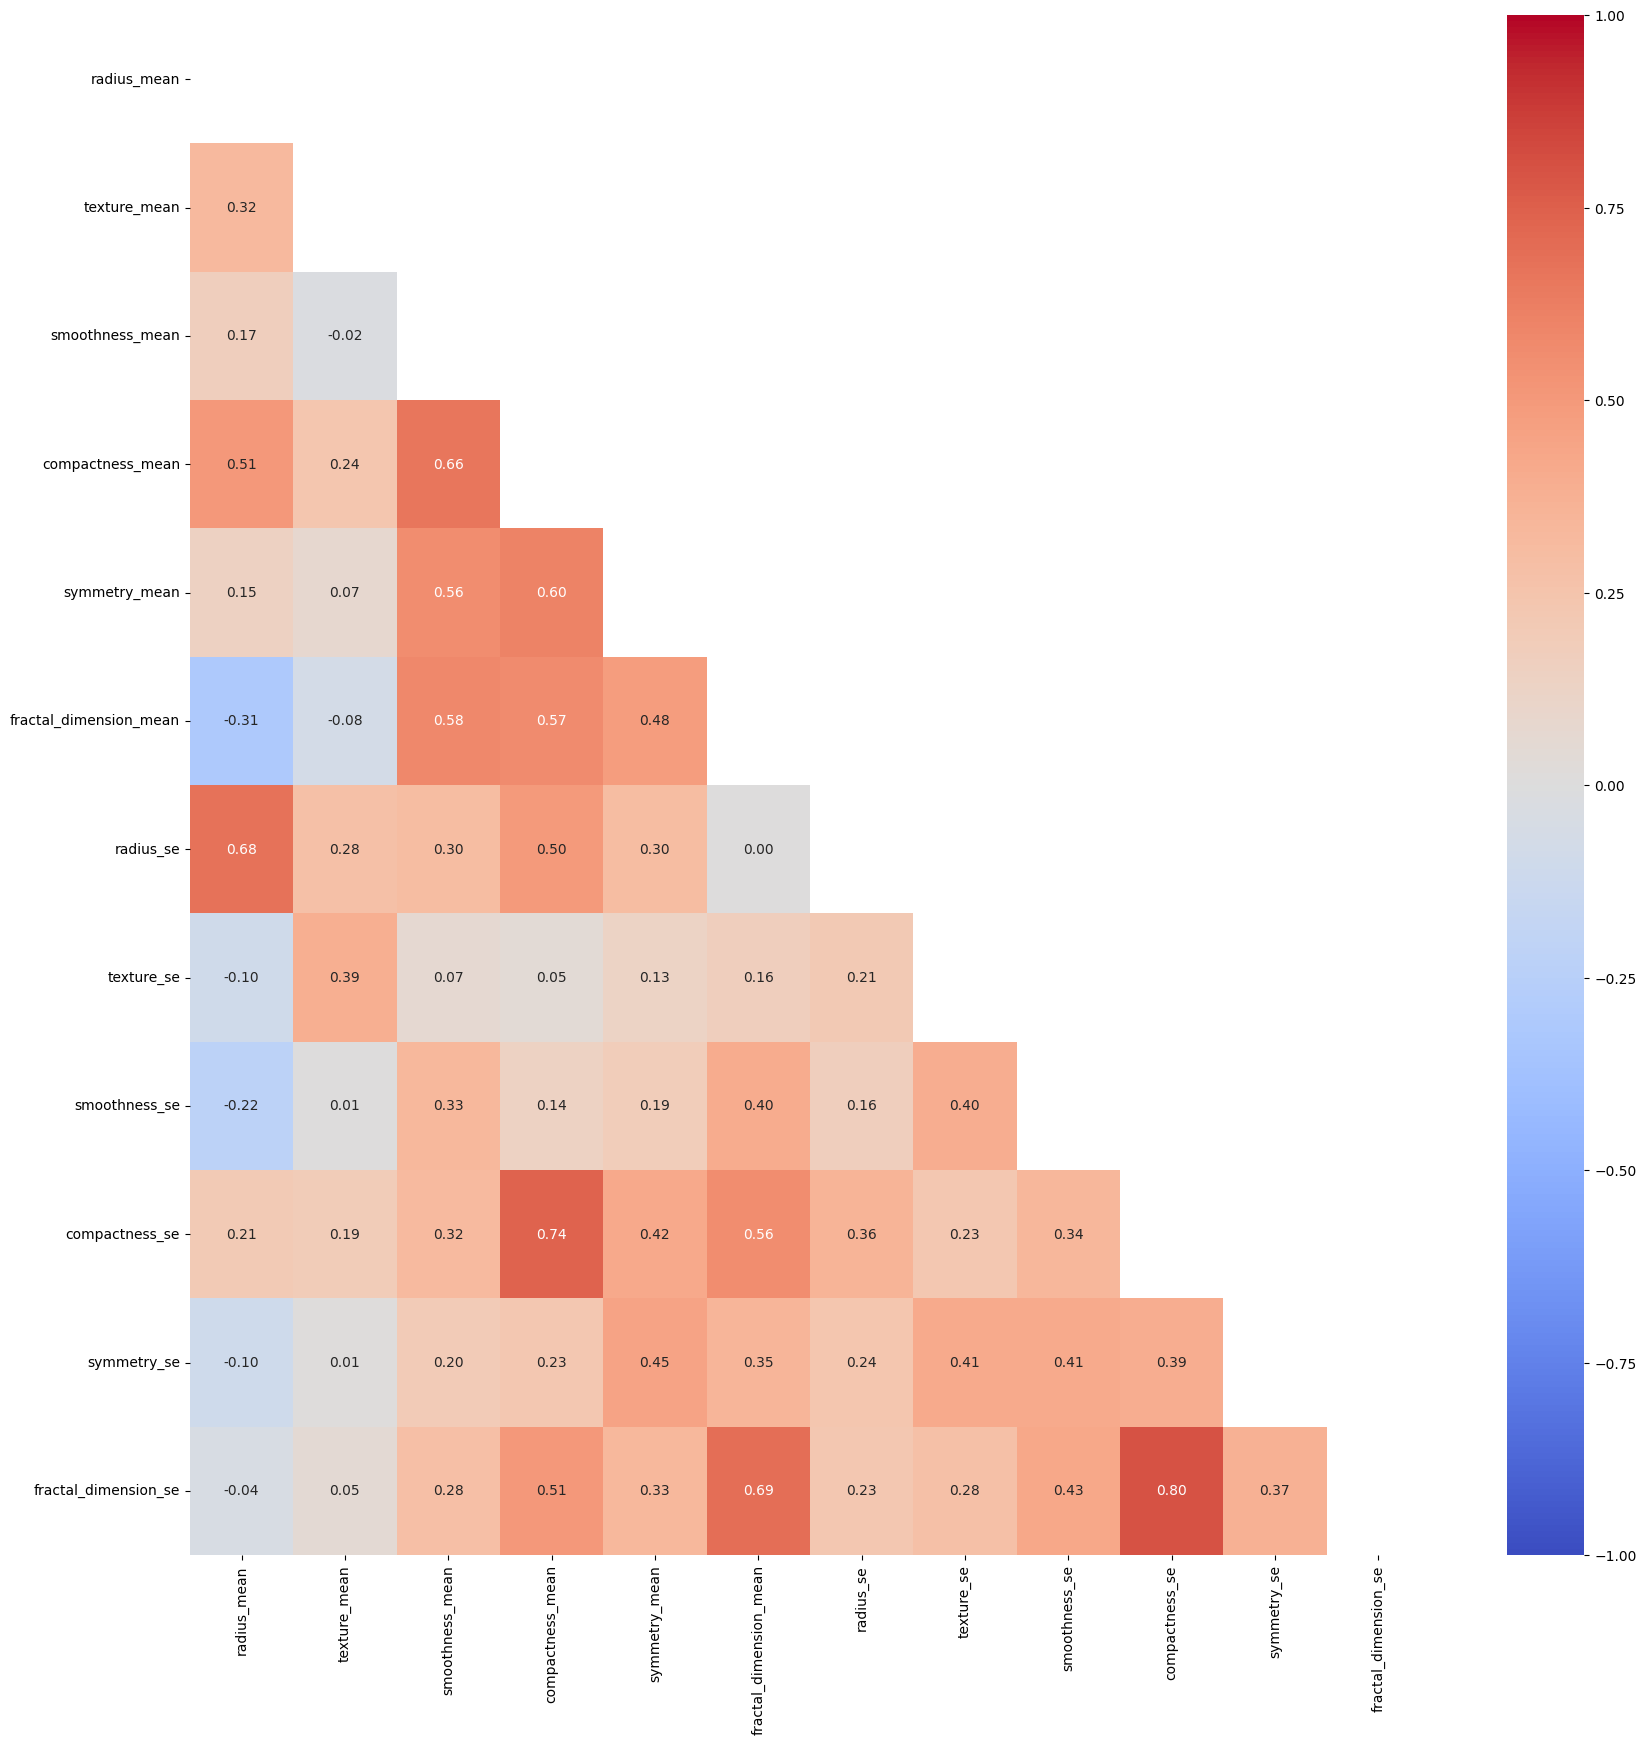

In [ ]:
corr = dc.corr(numeric_only=True)



plt.figure(figsize=(20,20))
sns.heatmap(corr,annot=True,fmt='.2f',mask=np.triu(corr),vmin=-1,vmax=1,center=0,cmap='coolwarm')
plt.show()

In [ ]:
dc['diagnosis'] = dc['diagnosis'].map({'M':1,'B':0})
dc.head()

,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,symmetry_se,fractal_dimension_se
0,1,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.03003,0.006193
1,1,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01389,0.003532
2,1,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.02250,0.004571
3,1,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05963,0.009208
4,1,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.01756,0.005115


In [ ]:
X=dc.drop(columns=['diagnosis'])
y=dc['diagnosis']

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train,y_train)

LogisticRegression()

In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score,f1_score,precision_score,recall_score

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test,y_pred)

accuracy

0.956140350877193

In [ ]:
recall_score(y_test,y_pred)


0.9534883720930233

In [ ]:
hc = pd.read_csv('/content/heart.csv')
hc.head(30)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [ ]:
hc.isna().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [ ]:
hc.duplicated().sum()

np.int64(0)

In [ ]:
sex_le = LabelEncoder()
hc['Sex']=sex_le.fit_transform(hc['Sex'])

In [ ]:
rest_ecg_le = LabelEncoder()
hc['RestingECG']=rest_ecg_le.fit_transform(hc['RestingECG'])

In [ ]:
ex_ang_le = LabelEncoder()
hc['ExerciseAngina']=ex_ang_le.fit_transform(hc['ExerciseAngina'])

In [ ]:
st_slope_le = LabelEncoder()
hc['ST_Slope']=st_slope_le.fit_transform(hc['ST_Slope'])

In [ ]:
hc_encoded = pd.get_dummies(hc,columns=['ChestPainType'])

In [ ]:
hc_encoded.head(50)

,Age,Sex,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA
0,40,1,140,289,0,1,172,0,0.0,2,0,False,True,False,False
1,49,0,160,180,0,1,156,0,1.0,1,1,False,False,True,False
2,37,1,130,283,0,2,98,0,0.0,2,0,False,True,False,False
3,48,0,138,214,0,1,108,1,1.5,1,1,True,False,False,False
4,54,1,150,195,0,1,122,0,0.0,2,0,False,False,True,False
5,39,1,120,339,0,1,170,0,0.0,2,0,False,False,True,False
6,45,0,130,237,0,1,170,0,0.0,2,0,False,True,False,False
7,54,1,110,208,0,1,142,0,0.0,2,0,False,True,False,False
8,37,1,140,207,0,1,130,1,1.5,1,1,True,False,False,False
9,48,0,120,284,0,1,120,0,0.0,2,0,False,True,False,False


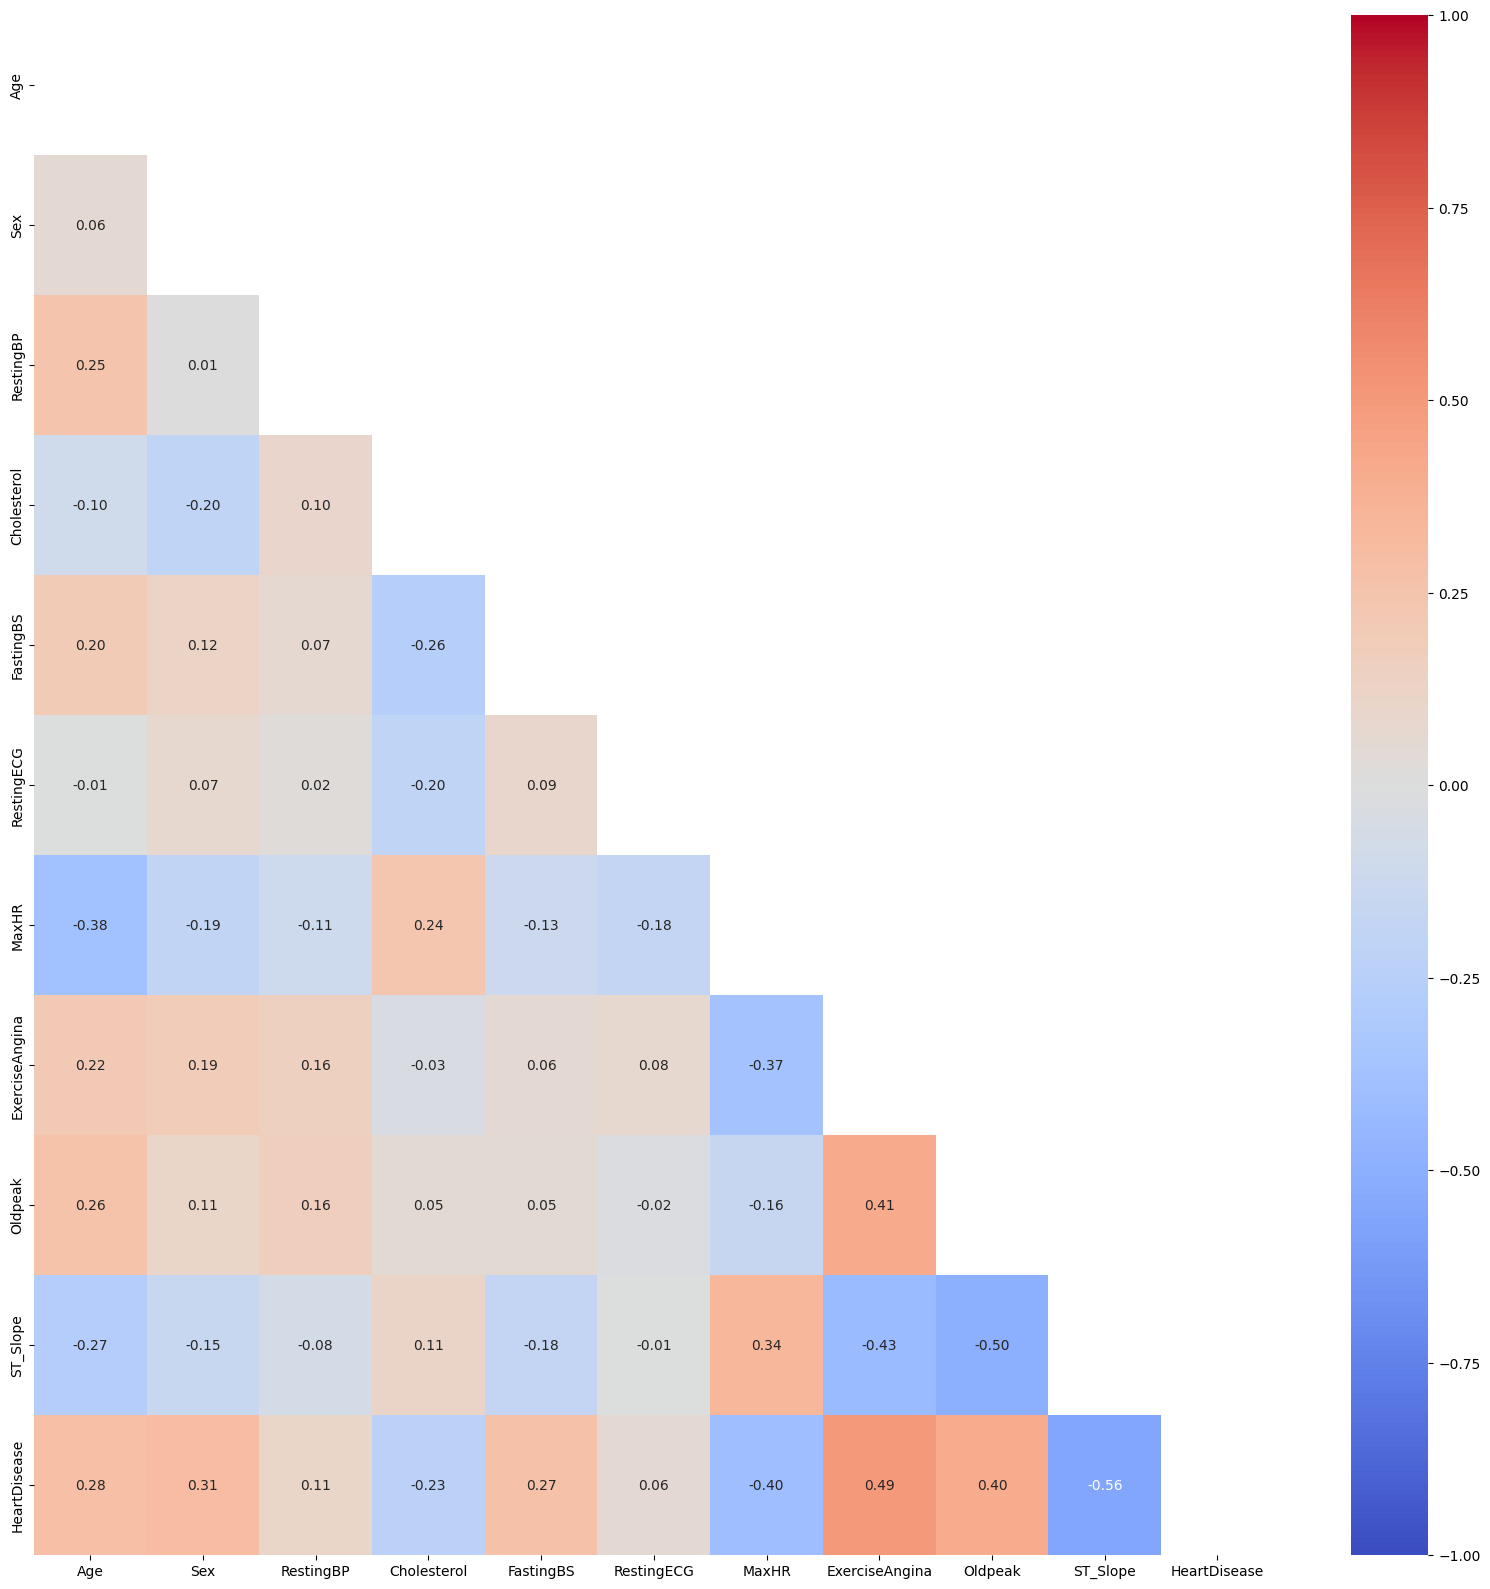

In [ ]:
corr = hc.corr(numeric_only=True)



plt.figure(figsize=(20,20))
sns.heatmap(corr,annot=True,fmt='.2f',mask=np.triu(corr),vmin=-1,vmax=1,center=0,cmap='coolwarm')
plt.show()

In [ ]:
X = hc_encoded.drop(columns=['HeartDisease'])
y = hc_encoded['HeartDisease']

In [ ]:
X

,Age,Sex,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA
0,40,1,140,289,0,1,172,0,0.0,2,False,True,False,False
1,49,0,160,180,0,1,156,0,1.0,1,False,False,True,False
2,37,1,130,283,0,2,98,0,0.0,2,False,True,False,False
3,48,0,138,214,0,1,108,1,1.5,1,True,False,False,False
4,54,1,150,195,0,1,122,0,0.0,2,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,110,264,0,1,132,0,1.2,1,False,False,False,True
914,68,1,144,193,1,1,141,0,3.4,1,True,False,False,False
915,57,1,130,131,0,1,115,1,1.2,1,True,False,False,False
916,57,0,130,236,0,0,174,0,0.0,1,False,True,False,False


In [ ]:
from sklearn.model_selection import train_test_split


X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler

numerical_cols=['Age','RestingBP','Cholesterol','FastingBS','MaxHR']

scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

In [ ]:
from sklearn.linear_model import LogisticRegression


model = LogisticRegression(fit_intercept=True,max_iter=1000)

model.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score,f1_score,precision_score,recall_score

In [ ]:
y_pred=model.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test,y_pred)

accuracy

0.842391304347826

In [ ]:
recall_score(y_test,y_pred)

0.8317757009345794

In [ ]:
confusion_matrix(y_test,y_pred)

array([[66, 11],
       [18, 89]])

In [ ]:
f1_score(y_test,y_pred)

0.8599033816425121

In [ ]:
bc = pd.read_csv('/content/boston.csv')
bc.head(30)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222.0,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311.0,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311.0,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311.0,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311.0,15.2,386.71,17.10,18.9


In [ ]:
bc.isna().sum()

,0
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0
TAX,0


In [ ]:
bc.duplicated().any()

np.False_

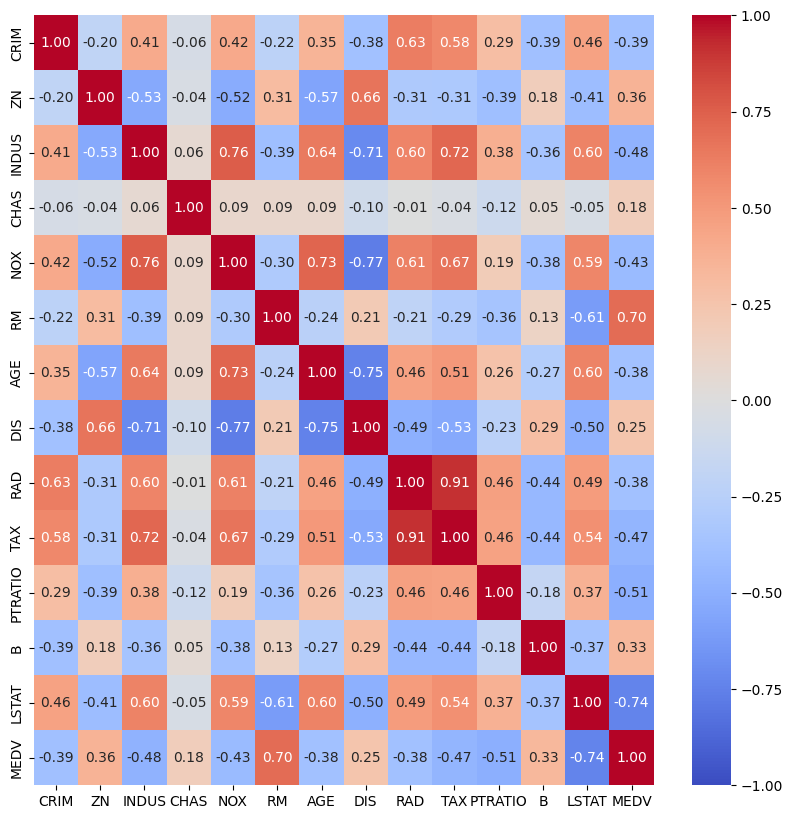

In [ ]:
corr = bc.corr()

plt.figure(figsize=(10,10))
sns.heatmap(corr,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='coolwarm')
plt.show()

In [ ]:
bc.drop(columns=['B','RAD'],inplace=True)

In [ ]:
X =bc.drop(columns=['MEDV'])
y = bc[['MEDV']]

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
X_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()
X_train = X_scaler.fit_transform(X_train)
X_test = X_scaler.transform(X_test)

y_train = y_scaler.fit_transform(y_train)
y_test = y_scaler.transform(y_test)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train,y_train)


LinearRegression()

In [ ]:
from sklearn.metrics import mean_squared_error,r2_score,root_mean_squared_error,mean_absolute_error

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
mean_squared_error(y_test,y_pred)

0.012266232789236024

In [ ]:
root_mean_squared_error(y_test,y_pred)

0.11075302609516376

In [ ]:
r2_score(y_test,y_pred)

0.6612867858746705

In [ ]:
mean_absolute_error(y_test,y_pred)

0.07227784383182134

In [ ]:
y_pred

array([[ 0.52971196],
       [ 0.69001387],
       [ 0.28627388],
       [ 0.44766817],
       [ 0.26703036],
       [ 0.42129009],
       [ 0.27904685],
       [ 0.2244768 ],
       [ 0.35730395],
       [ 0.35563448],
       [ 0.42822833],
       [ 0.29103927],
       [-0.20035357],
       [ 0.38455859],
       [ 0.31247143],
       [ 0.43688858],
       [ 0.31353569],
       [-0.02235689],
       [ 0.77430493],
       [ 0.23897813],
       [ 0.48434922],
       [ 0.54315451],
       [ 0.15480821],
       [ 0.44192214],
       [ 0.26547496],
       [ 0.20825855],
       [ 0.40541301],
       [ 0.27944773],
       [ 0.39010054],
       [ 0.32353099],
       [ 0.37992787],
       [ 0.44687889],
       [ 0.43069135],
       [ 0.24570698],
       [ 0.23337729],
       [ 0.29704311],
       [ 0.58704924],
       [ 0.32279271],
       [ 0.42440877],
       [ 0.44216901],
       [ 0.20345708],
       [ 0.57669492],
       [ 0.81214459],
       [ 0.28410885],
       [ 0.50796044],
       [ 0

In [ ]:
y_pred_inv = y_scaler.inverse_transform(y_pred)
y_pred_inv

array([[28.83703824],
       [36.05062396],
       [17.88232445],
       [25.14506779],
       [17.01636603],
       [23.9580539 ],
       [17.55710829],
       [15.10145605],
       [21.07867758],
       [21.00355163],
       [24.27027505],
       [18.09676719],
       [-4.01591084],
       [22.30513673],
       [19.06121432],
       [24.65998606],
       [19.1091061 ],
       [ 3.99393979],
       [39.84372196],
       [15.75401583],
       [26.79571508],
       [29.44195291],
       [11.96636936],
       [24.88649618],
       [16.94637321],
       [14.37163455],
       [23.24358534],
       [17.57514777],
       [22.55452431],
       [19.55889463],
       [22.09675436],
       [25.10954983],
       [24.38111059],
       [16.05681412],
       [15.50197803],
       [18.36693998],
       [31.41721571],
       [19.52567176],
       [24.09839447],
       [24.89760561],
       [14.15556874],
       [30.95127145],
       [41.54650673],
       [17.7848984 ],
       [27.8582197 ],
       [15

In [ ]:
cc = pd.read_csv('/content/California_Houses.csv.zip')
cc.head(30)

,Median_House_Value,Median_Income,Median_Age,Tot_Rooms,Tot_Bedrooms,Population,Households,Latitude,Longitude,Distance_to_coast,Distance_to_LA,Distance_to_SanDiego,Distance_to_SanJose,Distance_to_SanFrancisco
0,452600.0,8.3252,41,880,129,322,126,37.88,-122.23,9263.040773,556529.158342,735501.806984,67432.517001,21250.213767
1,358500.0,8.3014,21,7099,1106,2401,1138,37.86,-122.22,10225.733072,554279.850069,733236.884360,65049.908574,20880.600400
2,352100.0,7.2574,52,1467,190,496,177,37.85,-122.24,8259.085109,554610.717069,733525.682937,64867.289833,18811.487450
3,341300.0,5.6431,52,1274,235,558,219,37.85,-122.25,7768.086571,555194.266086,734095.290744,65287.138412,18031.047568
4,342200.0,3.8462,52,1627,280,565,259,37.85,-122.25,7768.086571,555194.266086,734095.290744,65287.138412,18031.047568
5,269700.0,4.0368,52,919,213,413,193,37.85,-122.25,7768.086571,555194.266086,734095.290744,65287.138412,18031.047568
6,299200.0,3.6591,52,2535,489,1094,514,37.84,-122.25,6843.020847,554364.406936,733249.808578,64315.991742,17538.209972
7,241400.0,3.1200,52,3104,687,1157,647,37.84,-122.25,6843.020847,554364.406936,733249.808578,64315.991742,17538.209972
8,226700.0,2.0804,42,2555,665,1206,595,37.84,-122.26,6363.948013,554949.749519,733820.824419,64751.463863,16744.406584
9,261100.0,3.6912,52,3549,707,1551,714,37.84,-122.25,6843.020847,554364.406936,733249.808578,64315.991742,17538.209972


In [ ]:
cc.isna().sum()

,0
Median_House_Value,0
Median_Income,0
Median_Age,0
Tot_Rooms,0
Tot_Bedrooms,0
Population,0
Households,0
Latitude,0
Longitude,0
Distance_to_coast,0


In [ ]:
cc.duplicated().any()

np.False_

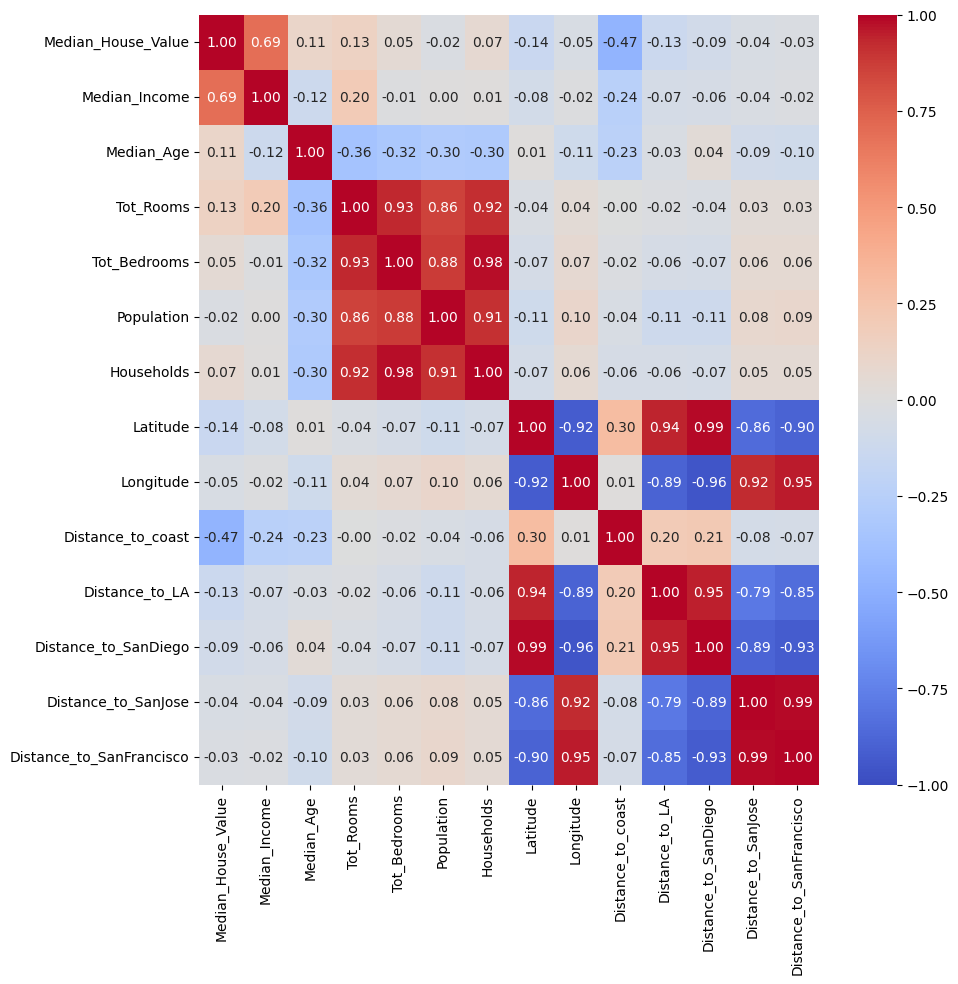

In [ ]:
corr = cc.corr()

plt.figure(figsize=(10,10))
sns.heatmap(corr,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='coolwarm')
plt.show()

In [ ]:
distance_cols = ['Distance_to_LA','Distance_to_SanDiego','Distance_to_SanJose','Distance_to_SanFrancisco']
cc.drop(columns=distance_cols,inplace=True)

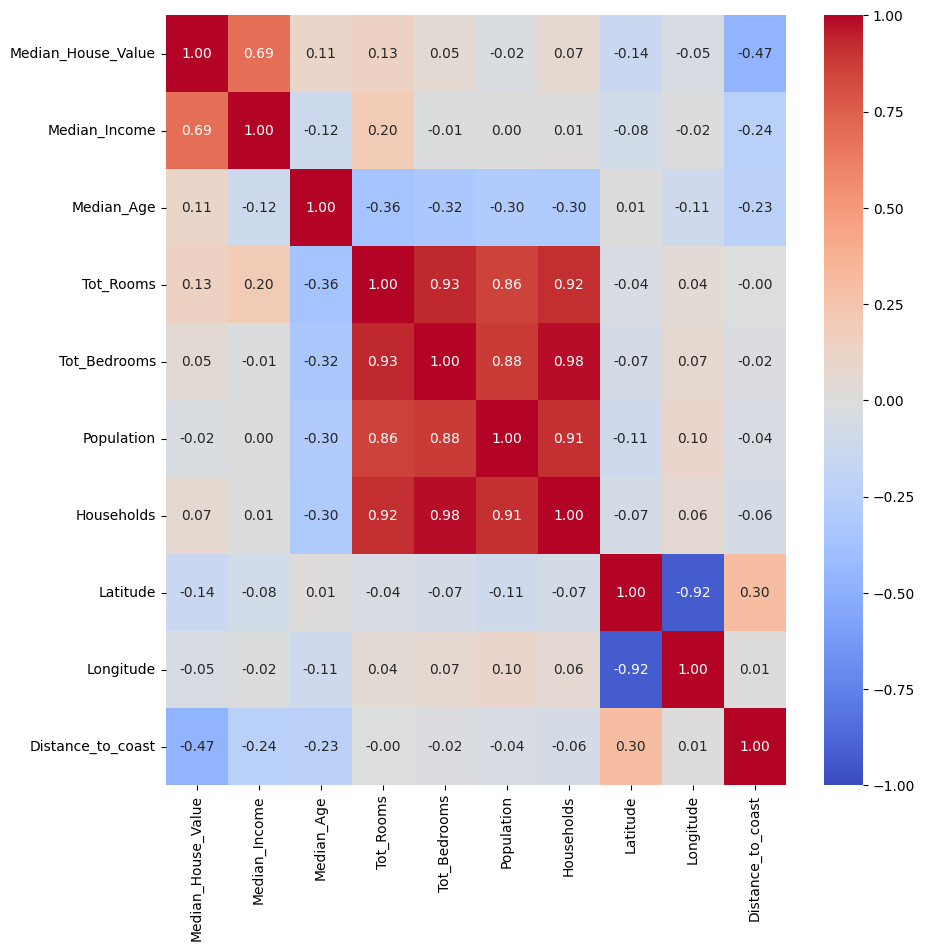

In [ ]:
corr = cc.corr()

plt.figure(figsize=(10,10))
sns.heatmap(corr,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='coolwarm')
plt.show()

In [ ]:
totat = ['Tot_Bedrooms']
cc.drop(columns=totat,inplace=True)

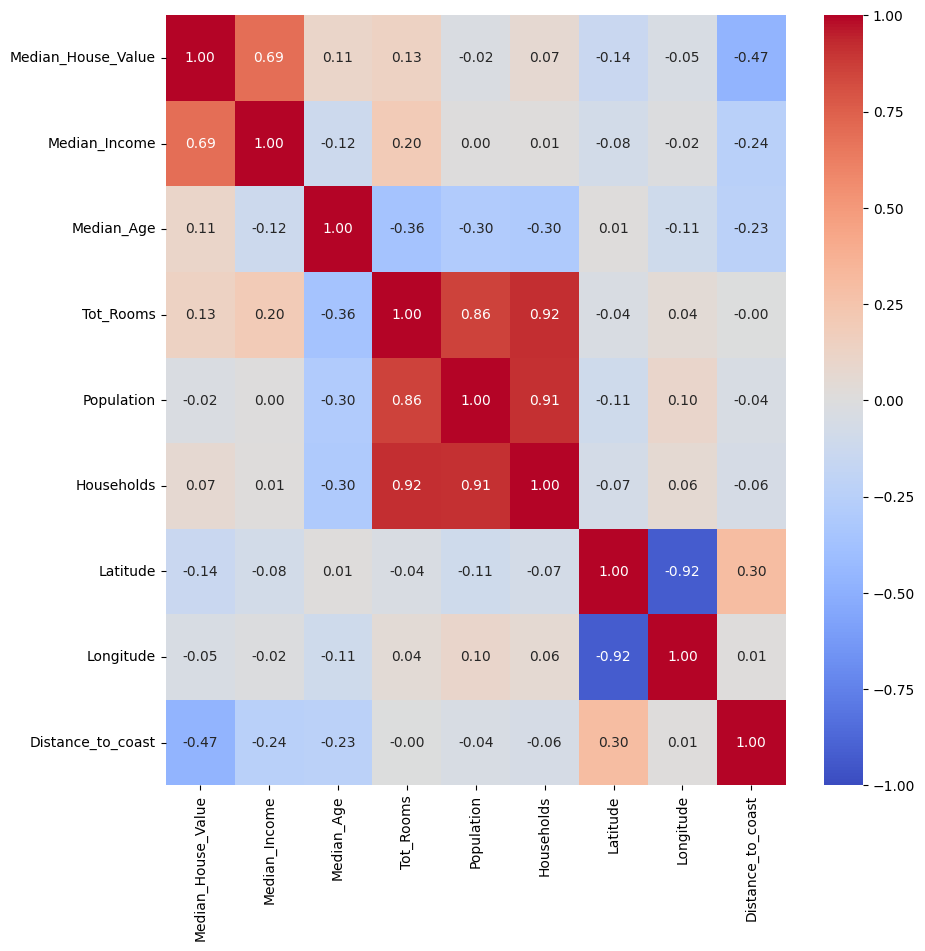

In [ ]:
corr = cc.corr()

plt.figure(figsize=(10,10))
sns.heatmap(corr,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='coolwarm')
plt.show()

In [ ]:
long = ['Longitude','Latitude']
cc.drop(columns=long,inplace=True)

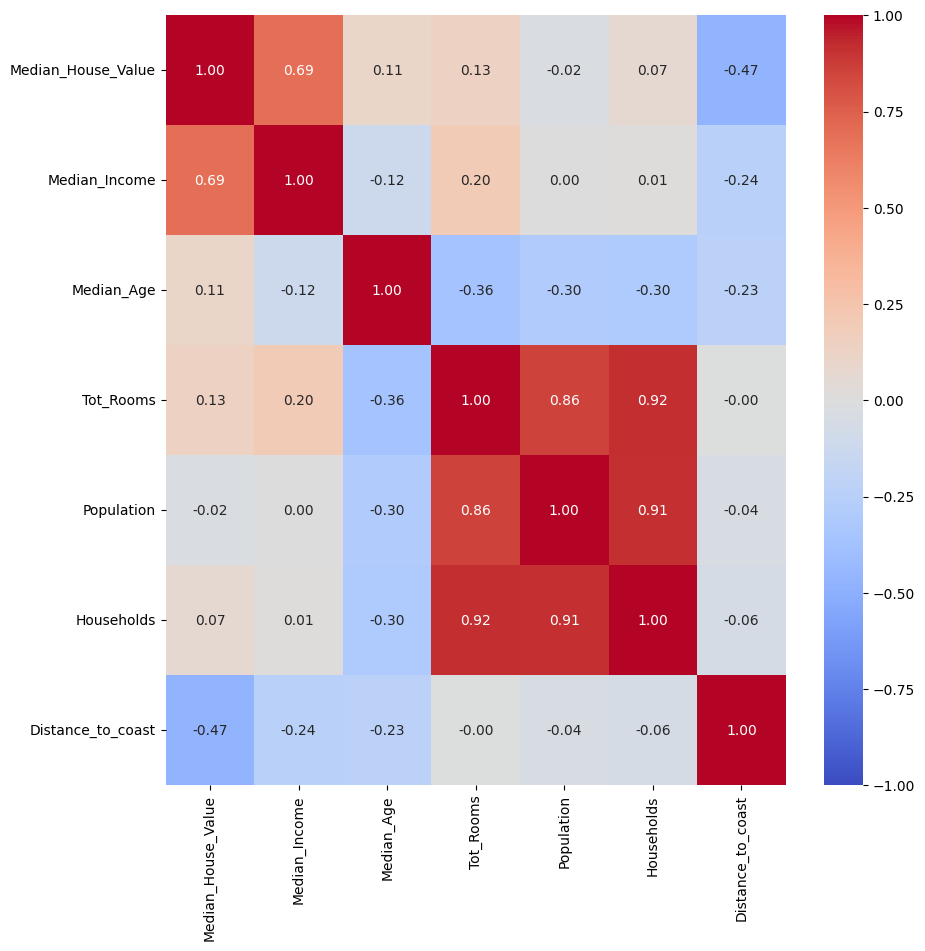

In [ ]:
corr = cc.corr()

plt.figure(figsize=(10,10))
sns.heatmap(corr,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='coolwarm')
plt.show()

In [ ]:
cc.head()

,Median_House_Value,Median_Income,Median_Age,Tot_Rooms,Population,Households,Distance_to_coast
0,452600.0,8.3252,41,880,322,126,9263.040773
1,358500.0,8.3014,21,7099,2401,1138,10225.733072
2,352100.0,7.2574,52,1467,496,177,8259.085109
3,341300.0,5.6431,52,1274,558,219,7768.086571
4,342200.0,3.8462,52,1627,565,259,7768.086571


In [ ]:
X = cc.drop('Median_House_Value',axis=1)
y = cc['Median_House_Value']

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
X_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()
X_train = X_scaler.fit_transform(X_train)
X_test = X_scaler.transform(X_test)

y_train = y_scaler.fit_transform(y_train.to_frame())
y_test = y_scaler.transform(y_test.to_frame())

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train,y_train)

LinearRegression()

In [ ]:
from sklearn.metrics import mean_squared_error,r2_score,root_mean_squared_error,mean_absolute_error

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
mean_squared_error(y_test,y_pred)

0.022023804584769744

In [ ]:
r2_score(y_test,y_pred)

0.6046583741607213

In [ ]:
root_mean_squared_error(y_test,y_pred)

0.14840419328566745

In [ ]:
mean_absolute_error(y_test,y_pred)

0.1091808205597471

In [ ]:
tc = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')
tc.head(30)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [ ]:
tc.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
tc.duplicated().any()

np.False_

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder

In [ ]:
le_gender= LabelEncoder()

tc['gender']=le_gender.fit_transform(tc['gender'])

In [ ]:
le_partner = LabelEncoder()

tc['Partner']=le_partner.fit_transform(tc['Partner'])

In [ ]:
le_phone = LabelEncoder()

tc['PhoneService']=le_phone.fit_transform(tc['PhoneService'])

In [ ]:
le_dependents = LabelEncoder()

tc['Dependents']=le_dependents.fit_transform(tc['Dependents'])

In [ ]:
tc.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,1,0,0,0,34,1,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,1,0,0,0,2,1,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,1,0,0,0,45,0,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,0,0,0,0,2,1,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
tc.drop(columns=['customerID'],inplace=True)

In [ ]:
tc.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
mobile_lines = LabelEncoder()

tc['MultipleLines']=mobile_lines.fit_transform(tc['MultipleLines'])

In [ ]:
churn = LabelEncoder()

tc['Churn']=churn.fit_transform(tc['Churn'])

In [ ]:
tc_encoded = pd.get_dummies(tc,columns=['InternetService','Contract','PaymentMethod','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies'])

In [ ]:
tc_encoded.head(30)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,PaperlessBilling,MonthlyCharges,TotalCharges,...,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes
0,0,0,1,0,1,0,1,Yes,29.85,29.85,...,False,True,False,False,True,False,False,True,False,False
1,1,0,0,0,34,1,0,No,56.95,1889.5,...,True,True,False,False,True,False,False,True,False,False
2,1,0,0,0,2,1,0,Yes,53.85,108.15,...,False,True,False,False,True,False,False,True,False,False
3,1,0,0,0,45,0,1,No,42.30,1840.75,...,True,False,False,True,True,False,False,True,False,False
4,0,0,0,0,2,1,0,Yes,70.70,151.65,...,False,True,False,False,True,False,False,True,False,False
5,0,0,0,0,8,1,2,Yes,99.65,820.5,...,True,True,False,False,False,False,True,False,False,True
6,1,0,0,1,22,1,2,Yes,89.10,1949.4,...,False,True,False,False,False,False,True,True,False,False
7,0,0,0,0,10,0,1,No,29.75,301.9,...,False,True,False,False,True,False,False,True,False,False
8,0,0,1,0,28,1,2,Yes,104.80,3046.05,...,True,False,False,True,False,False,True,False,False,True
9,1,0,0,1,62,1,0,No,56.15,3487.95,...,False,True,False,False,True,False,False,True,False,False


In [ ]:
paperless = LabelEncoder()

tc_encoded['PaperlessBilling']=paperless.fit_transform(tc_encoded['PaperlessBilling'])

In [ ]:
tc_encoded['TotalCharges']=pd.to_numeric(tc_encoded['TotalCharges'],errors='coerce')
tc_encoded['TotalCharges'].fillna(tc_encoded['TotalCharges'].mean(),inplace=True)

/tmp/ipython-input-153-1830294298.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  tc_encoded['TotalCharges'].fillna(tc_encoded['TotalCharges'].mean(),inplace=True)


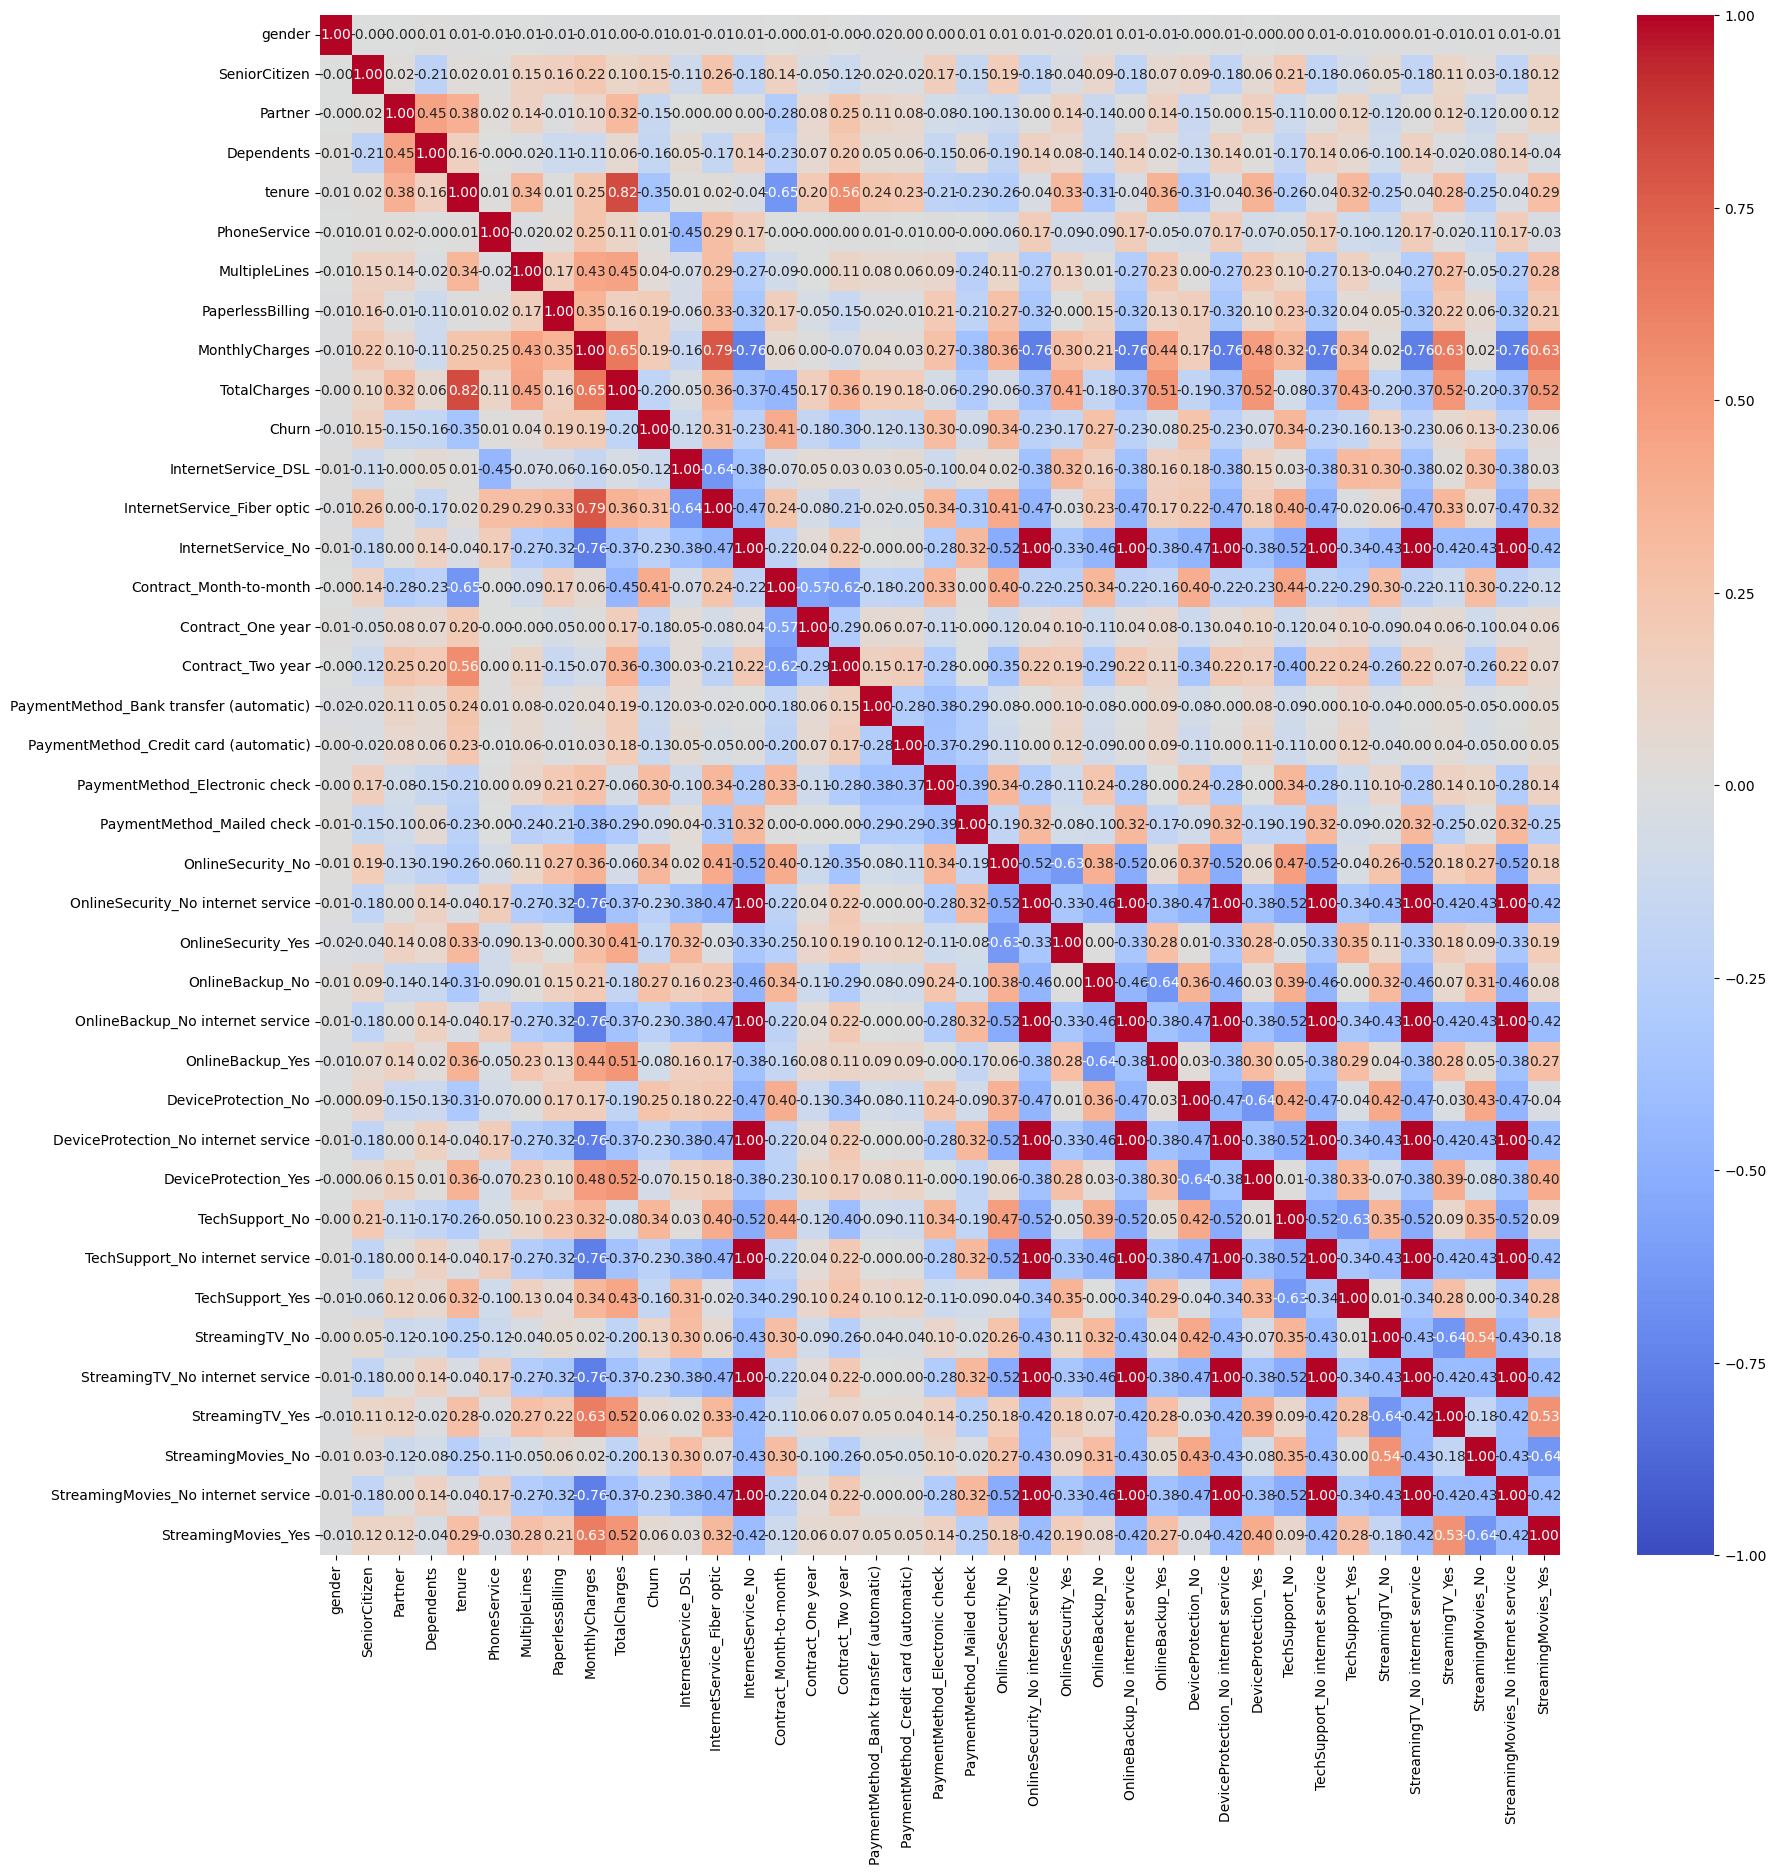

In [ ]:
corr = tc_encoded.corr(numeric_only=True)



plt.figure(figsize=(20,20))
sns.heatmap(corr,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='coolwarm')
plt.show()

In [ ]:
X = tc_encoded.drop(columns=['Churn'])
y = tc_encoded['Churn']

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
tc_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 39 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   7043 non-null   int64  
 1   SeniorCitizen                            7043 non-null   int64  
 2   Partner                                  7043 non-null   int64  
 3   Dependents                               7043 non-null   int64  
 4   tenure                                   7043 non-null   int64  
 5   PhoneService                             7043 non-null   int64  
 6   MultipleLines                            7043 non-null   int64  
 7   PaperlessBilling                         7043 non-null   int64  
 8   MonthlyCharges                           7043 non-null   float64
 9   TotalCharges                             7043 non-null   float64
 10  Churn                                    7043 no

In [ ]:

from sklearn.preprocessing import StandardScaler
numerical_cols = ['tenure','MonthlyCharges','TotalCharges']
scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train,y_train)

LogisticRegression()

In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score,f1_score,precision_score,recall_score

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test,y_pred)

accuracy

0.8218594748048261

In [ ]:
confusion_matrix(y_test,y_pred)

array([[934, 102],
       [149, 224]])

In [ ]:
recall_score(y_test,y_pred)

0.6005361930294906

In [ ]:
precision_score(y_test,y_pred)

0.6871165644171779

In [ ]:
f1_score(y_test,y_pred)

0.6409155937052933

In [ ]:
# Decision Trees

In [ ]:
df = pd.read_csv('/content/Customer-Churn-Records.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [ ]:
df.isna().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [ ]:
df.duplicated().any()

np.False_

In [ ]:
df.drop(columns=['RowNumber','CustomerId','Surname'],inplace=True)

In [ ]:
df.drop(columns=['Card Type'],inplace=True)

In [ ]:
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,1,2,464,True,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,1,3,456,False,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1,3,377,True,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,5,350,True,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,5,425,False,False,True


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Gender']=le.fit_transform(df['Gender'])

In [ ]:
#df = pd.get_dummies(df,columns=['Geography'])
#df.head()

In [ ]:
X = df.drop(columns=['Exited'])
y = df['Exited']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier()

decision_tree.fit(X_train,y_train)

DecisionTreeClassifier()

In [ ]:
from sklearn.metrics import accuracy_score


In [ ]:
y_pred = decision_tree.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test,y_pred)

accuracy


0.9975

In [ ]:
#Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()

rf.fit(X_train,y_train)

RandomForestClassifier()

In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
y_pred = rf.predict(X_test)

accuracy_score(y_test,y_pred)

0.999

In [ ]:
pip install catboost lightgbm xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.5 MB/s eta 0:00:00


In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb = XGBClassifier()

xgb.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

In [ ]:
y_pred = xgb.predict(X_test)

accuracy_score(y_test,y_pred)


0.999

In [ ]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier()

lgbm.fit(X_train,y_train)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1645, number of negative: 6355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001288 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1121
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.205625 -> initscore=-1.351502
[LightGBM] [Info] Start training from score -1.351502
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


LGBMClassifier()

In [ ]:
y_pred = lgbm.predict(X_test)

accuracy_score(y_test,y_pred)

0.999

In [ ]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier()

cat.fit(X_train,y_train)

Learning rate set to 0.025035
0:	learn: 0.6130919	total: 57.9ms	remaining: 57.8s
1:	learn: 0.5411608	total: 74.5ms	remaining: 37.2s
2:	learn: 0.4783047	total: 84ms	remaining: 27.9s
3:	learn: 0.4233734	total: 102ms	remaining: 25.3s
4:	learn: 0.3743881	total: 109ms	remaining: 21.6s
5:	learn: 0.3328601	total: 115ms	remaining: 19.1s
6:	learn: 0.2961780	total: 119ms	remaining: 16.9s
7:	learn: 0.2647460	total: 124ms	remaining: 15.3s
8:	learn: 0.2372609	total: 143ms	remaining: 15.7s
9:	learn: 0.2121356	total: 148ms	remaining: 14.6s
10:	learn: 0.1899303	total: 152ms	remaining: 13.6s
11:	learn: 0.1701311	total: 156ms	remaining: 12.8s
12:	learn: 0.1518447	total: 160ms	remaining: 12.1s
13:	learn: 0.1364774	total: 166ms	remaining: 11.7s
14:	learn: 0.1225289	total: 169ms	remaining: 11.1s
15:	learn: 0.1115707	total: 174ms	remaining: 10.7s
16:	learn: 0.1016618	total: 178ms	remaining: 10.3s
17:	learn: 0.0924719	total: 183ms	remaining: 9.99s
18:	learn: 0.0839741	total: 189ms	remaining: 9.75s
19:	learn:

In [ ]:
y_pred = cat.predict(X_test)

accuracy_score(y_test,y_pred)

0.999

In [ ]:
cc = pd.read_csv('/content/California_Houses.csv.zip')
cc.head(30)

,Median_House_Value,Median_Income,Median_Age,Tot_Rooms,Tot_Bedrooms,Population,Households,Latitude,Longitude,Distance_to_coast,Distance_to_LA,Distance_to_SanDiego,Distance_to_SanJose,Distance_to_SanFrancisco
0,452600.0,8.3252,41,880,129,322,126,37.88,-122.23,9263.040773,556529.158342,735501.806984,67432.517001,21250.213767
1,358500.0,8.3014,21,7099,1106,2401,1138,37.86,-122.22,10225.733072,554279.850069,733236.884360,65049.908574,20880.600400
2,352100.0,7.2574,52,1467,190,496,177,37.85,-122.24,8259.085109,554610.717069,733525.682937,64867.289833,18811.487450
3,341300.0,5.6431,52,1274,235,558,219,37.85,-122.25,7768.086571,555194.266086,734095.290744,65287.138412,18031.047568
4,342200.0,3.8462,52,1627,280,565,259,37.85,-122.25,7768.086571,555194.266086,734095.290744,65287.138412,18031.047568
5,269700.0,4.0368,52,919,213,413,193,37.85,-122.25,7768.086571,555194.266086,734095.290744,65287.138412,18031.047568
6,299200.0,3.6591,52,2535,489,1094,514,37.84,-122.25,6843.020847,554364.406936,733249.808578,64315.991742,17538.209972
7,241400.0,3.1200,52,3104,687,1157,647,37.84,-122.25,6843.020847,554364.406936,733249.808578,64315.991742,17538.209972
8,226700.0,2.0804,42,2555,665,1206,595,37.84,-122.26,6363.948013,554949.749519,733820.824419,64751.463863,16744.406584
9,261100.0,3.6912,52,3549,707,1551,714,37.84,-122.25,6843.020847,554364.406936,733249.808578,64315.991742,17538.209972


In [ ]:
cc.isna().sum()

,0
Median_House_Value,0
Median_Income,0
Median_Age,0
Tot_Rooms,0
Tot_Bedrooms,0
Population,0
Households,0
Latitude,0
Longitude,0
Distance_to_coast,0


In [ ]:
cc.duplicated().any()

np.False_

In [ ]:
cc.drop(columns=['Longitude','Latitude'],inplace=True)

In [ ]:
cc.drop(columns=['Tot_Bedrooms'],inplace=True)

In [ ]:
cc.drop(columns=['Distance_to_LA','Distance_to_SanDiego','Distance_to_SanJose','Distance_to_SanFrancisco'],inplace=True)

In [ ]:
X = cc.drop(columns=['Median_House_Value'])
y = cc['Median_House_Value']

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeRegressor

decision_tree = DecisionTreeRegressor()

decision_tree.fit(X_train,y_train)

DecisionTreeRegressor()

In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
y_pred = decision_tree.predict(X_test)

In [ ]:
accuracy_score(y_test,y_pred)

0.02252906976744186

In [ ]:
bc = pd.read_csv('/content/boston.csv')
bc.head(30)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222.0,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311.0,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311.0,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311.0,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311.0,15.2,386.71,17.10,18.9


In [ ]:
bc.isna().sum()

,0
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0
TAX,0


In [ ]:
bc.duplicated().any()

np.False_

In [ ]:
X = bc.drop(columns=['MEDV'])
y = bc['MEDV']

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
decision_tree = DecisionTreeRegressor(criterion='squared_error',splitter='best',max_depth=10,min_samples_split=2)

decision_tree.fit(X_train,y_train)

DecisionTreeRegressor(max_depth=10)

In [ ]:
y_pred = decision_tree.predict(X_test)

In [ ]:
from sklearn.metrics import mean_squared_error,r2_score,root_mean_squared_error,mean_absolute_error

In [ ]:
r2_score(y_test,y_pred)


0.8559791261123338

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion':['squared_error','absolute_error','friedman_mse'],
    'splitter':['best','random'],
    'max_depth':[None,10,100],
    'min_samples_split':[2,3,4],
    'random_state':[42]
}

decision_tree = DecisionTreeRegressor()

grid_search = GridSearchCV(decision_tree,param_grid,cv=5)

grid_search.fit(X_train,y_train)


GridSearchCV(cv=5, estimator=DecisionTreeRegressor(),
             param_grid={'criterion': ['squared_error', 'absolute_error',
                                       'friedman_mse'],
                         'max_depth': [None, 10, 100],
                         'min_samples_split': [2, 3, 4], 'random_state': [42],
                         'splitter': ['best', 'random']})

In [ ]:
grid_search.best_params_

{'criterion': 'absolute_error',
 'max_depth': 10,
 'min_samples_split': 4,
 'random_state': 42,
 'splitter': 'best'}

In [ ]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

r2_score(y_test,y_pred)

0.6174047532580407

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_grid = {
    'max_depth': [None,3,100],
    'max_features':randint(1,9),
    'min_samples_leaf':randint(2,9)
}

decision_tree = DecisionTreeRegressor()

random_search = RandomizedSearchCV(decision_tree,param_grid,cv=5)

random_search.fit(X_train,y_train)


RandomizedSearchCV(cv=5, estimator=DecisionTreeRegressor(),
                   param_distributions={'max_depth': [None, 3, 100],
                                        'max_features': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7c96f6272510>,
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7c96f6272ed0>})

In [ ]:
random_search.best_params_

{'max_depth': None, 'max_features': 6, 'min_samples_leaf': 2}

In [ ]:
best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

r2_score(y_test,y_pred)

0.7286238051456502

In [ ]:
#bayesian optimization: check optuna

In [ ]:
#breast cancer train with all and use hyper parameter three models

In [ ]:
bc = pd.read_csv('/content/data.csv')
bc.head(30)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.990,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.71190,0.26540,0.4601,0.11890,NaN
1,842517,M,20.570,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.24160,0.18600,0.2750,0.08902,NaN
2,84300903,M,19.690,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.45040,0.24300,0.3613,0.08758,NaN
3,84348301,M,11.420,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.68690,0.25750,0.6638,0.17300,NaN
4,84358402,M,20.290,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.40000,0.16250,0.2364,0.07678,NaN
5,843786,M,12.450,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,23.75,103.40,741.6,0.1791,0.5249,0.53550,0.17410,0.3985,0.12440,NaN
6,844359,M,18.250,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,27.66,153.20,1606.0,0.1442,0.2576,0.37840,0.19320,0.3063,0.08368,NaN
7,84458202,M,13.710,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,28.14,110.60,897.0,0.1654,0.3682,0.26780,0.15560,0.3196,0.11510,NaN
8,844981,M,13.000,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,30.73,106.20,739.3,0.1703,0.5401,0.53900,0.20600,0.4378,0.10720,NaN
9,84501001,M,12.460,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,40.68,97.65,711.4,0.1853,1.0580,1.10500,0.22100,0.4366,0.20750,NaN


In [ ]:
bc.isna().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [ ]:
bc.duplicated().any()

np.False_

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
bc['diagnosis']=le.fit_transform(bc['diagnosis'])

In [ ]:
bc.drop(columns=['Unnamed: 32'],inplace=True)

In [ ]:
worst_cols = ['radius_worst','texture_worst','perimeter_worst','area_worst','smoothness_worst','compactness_worst','concavity_worst','concave points_worst','symmetry_worst','fractal_dimension_worst']

In [ ]:
bc.drop(columns=worst_cols,inplace=True)

In [ ]:
perimeter_and_area_cols = ['perimeter_mean','area_mean','perimeter_se','area_se']

In [ ]:
bc.drop(columns=perimeter_and_area_cols,inplace=True)

In [ ]:
concavity_cols = ['concavity_mean','concave points_mean']

In [ ]:
bc.drop(columns=concavity_cols,inplace=True)

In [ ]:
X = bc.drop(columns=['diagnosis'])
y = bc['diagnosis']

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier()

decision_tree.fit(X_train,y_train)

DecisionTreeClassifier()

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion':['squared_error','absolute_error','friedman_mse'],
    'splitter':['best','random'],
    'max_depth':[None,10,100],
    'min_samples_split':[2,3,4],
    'random_state':[42]
}

decision_tree = DecisionTreeClassifier()

grid_search = GridSearchCV(decision_tree,param_grid,cv=5)

#grid_search.fit(X_train,y_train)

In [ ]:
from sklearn.metrics import accuracy_score,r2_score

In [ ]:
#y_pred = grid_search.predict(X_test)

In [ ]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

r2_score(y_test,y_pred)

0.4398951850638716

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_grid = {
    'max_depth': [None,3,100],
    'max_features':randint(1,9),
    'min_samples_leaf':randint(2,9)
}

decision_tree = DecisionTreeRegressor()

random_search = RandomizedSearchCV(decision_tree,param_grid,cv=5)

random_search.fit(X_train,y_train)

RandomizedSearchCV(cv=5, estimator=DecisionTreeRegressor(),
                   param_distributions={'max_depth': [None, 3, 100],
                                        'max_features': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7ee76bc11490>,
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7ee76bb8d9d0>})

In [ ]:
model = random_search.best_estimator_

y_pred = model.predict(X_test)

r2_score(y_test,y_pred)

0.7742579876355042

In [ ]:
decision_tree = DecisionTreeRegressor(criterion='squared_error',splitter='best',max_depth=10,min_samples_split=2)

decision_tree.fit(X_train,y_train)

DecisionTreeRegressor(max_depth=10)

In [ ]:
y_pred = decision_tree.predict(X_test)

In [ ]:
model = random_search.best_estimator_

y_pred = model.predict(X_test)

r2_score(y_test,y_pred)

0.7742579876355042

In [ ]:
df = pd.read_csv('/content/heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
df.isna().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [ ]:
df.duplicated().any()

np.False_

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [ ]:
df['Sex'].unique()

array(['M', 'F'], dtype=object)

In [ ]:
df['ChestPainType'].unique()

array(['ATA', 'NAP', 'ASY', 'TA'], dtype=object)

In [ ]:
df['RestingECG'].unique()

array(['Normal', 'ST', 'LVH'], dtype=object)

In [ ]:
df['ExerciseAngina'].unique()

array(['N', 'Y'], dtype=object)

In [ ]:
le = LabelEncoder()
df['Sex']=le.fit_transform(df['Sex'])

In [ ]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,0,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,1,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,0,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,1,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
le = LabelEncoder()
df['ExerciseAngina']=le.fit_transform(df['ExerciseAngina'])

In [ ]:
df['RestingECG']=df['RestingECG'].map({'ST':0,'Normal':1,'LVH':2})

In [ ]:
df['ST_Slope']=df['ST_Slope'].map({'Down':0,'Flat':1,'Up':2})

In [ ]:
df_encoded = pd.get_dummies(df,columns=['ChestPainType'])

In [ ]:
df_encoded.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA
0,40,1,140,289,0,1,172,0,0.0,2,0,False,True,False,False
1,49,0,160,180,0,1,156,0,1.0,1,1,False,False,True,False
2,37,1,130,283,0,0,98,0,0.0,2,0,False,True,False,False
3,48,0,138,214,0,1,108,1,1.5,1,1,True,False,False,False
4,54,1,150,195,0,1,122,0,0.0,2,0,False,False,True,False


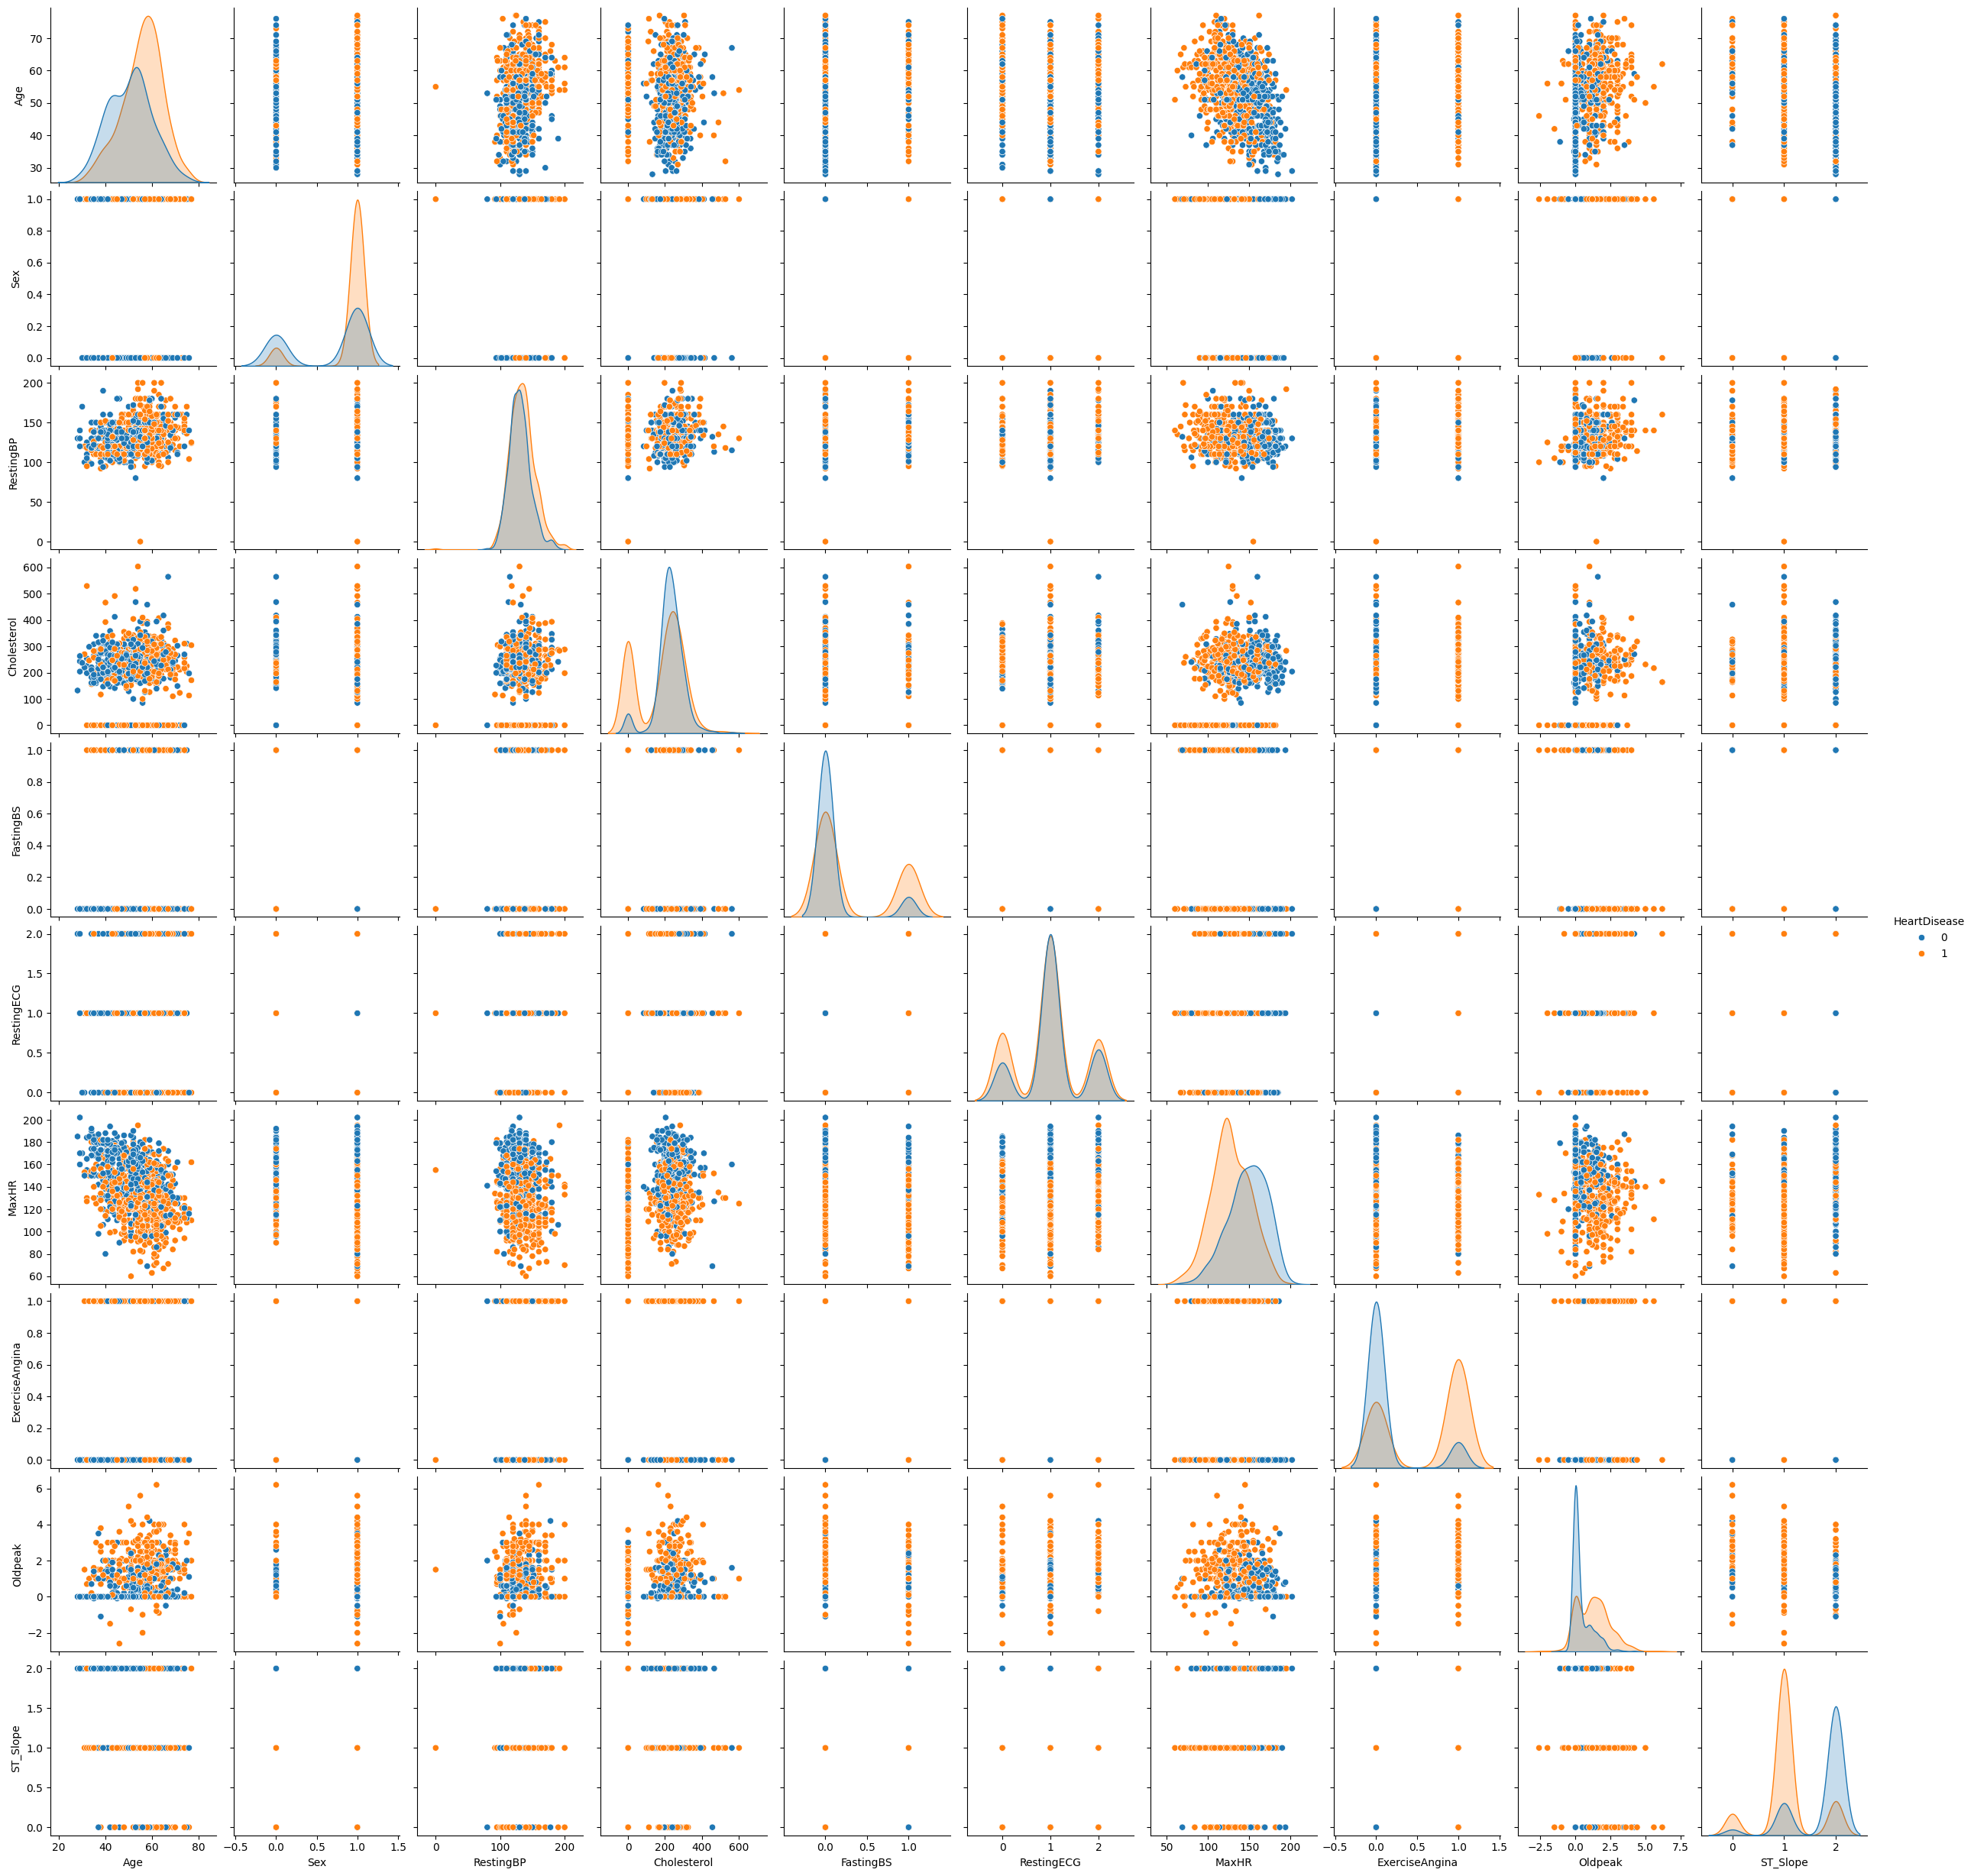

In [ ]:
sns.pairplot(df,hue='HeartDisease')

In [ ]:
X = df_encoded.drop(columns=['HeartDisease'])
y = df['HeartDisease']

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from sklearn.ensemble import VotingClassifier

cb = CatBoostClassifier()
lgbm = LGBMClassifier()
xgb = XGBClassifier()

voting_classifier = VotingClassifier(estimators=[('cb',cb),('lgbm',lgbm),('xgb',xgb)])

voting_classifier.fit(X_train,y_train)

Learning rate set to 0.009028
0:	learn: 0.6860989	total: 51.5ms	remaining: 51.5s
1:	learn: 0.6787320	total: 57.1ms	remaining: 28.5s
2:	learn: 0.6721981	total: 58.8ms	remaining: 19.5s
3:	learn: 0.6647140	total: 66.5ms	remaining: 16.6s
4:	learn: 0.6576466	total: 71.8ms	remaining: 14.3s
5:	learn: 0.6495252	total: 76.5ms	remaining: 12.7s
6:	learn: 0.6419657	total: 80.5ms	remaining: 11.4s
7:	learn: 0.6357401	total: 83.2ms	remaining: 10.3s
8:	learn: 0.6322685	total: 83.9ms	remaining: 9.23s
9:	learn: 0.6254758	total: 89.4ms	remaining: 8.85s
10:	learn: 0.6198276	total: 91ms	remaining: 8.18s
11:	learn: 0.6136313	total: 94.8ms	remaining: 7.8s
12:	learn: 0.6082421	total: 105ms	remaining: 7.97s
13:	learn: 0.6011978	total: 114ms	remaining: 8.03s
14:	learn: 0.5956560	total: 121ms	remaining: 7.93s
15:	learn: 0.5891260	total: 127ms	remaining: 7.81s
16:	learn: 0.5835012	total: 133ms	remaining: 7.7s
17:	learn: 0.5773097	total: 135ms	remaining: 7.36s
18:	learn: 0.5716459	total: 142ms	remaining: 7.31s
19:

VotingClassifier(estimators=[('cb',
                              <catboost.core.CatBoostClassifier object at 0x7f771cc27110>),
                             ('lgbm', LGBMClassifier()),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric=None,
                                            feature_types=None...
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None,
                                            random_state=None, ...))])

In [ ]:
from sklearn.metrics import accuracy_score,recall_score


y_pred = voting_classifier.predict(X_test)

In [ ]:
accuracy_score(y_test,y_pred)

0.8858695652173914

In [ ]:
recall_score(y_test,y_pred)

0.897196261682243

In [ ]:
mc = pd.read_csv('/content/mushrooms.csv')
mc.head(30)

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
5,e,x,y,y,t,a,f,c,b,n,...,s,w,w,p,w,o,p,k,n,g
6,e,b,s,w,t,a,f,c,b,g,...,s,w,w,p,w,o,p,k,n,m
7,e,b,y,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,s,m
8,p,x,y,w,t,p,f,c,n,p,...,s,w,w,p,w,o,p,k,v,g
9,e,b,s,y,t,a,f,c,b,g,...,s,w,w,p,w,o,p,k,s,m


In [ ]:
mc.isna().sum()

,0
class,0
cap-shape,0
cap-surface,0
cap-color,0
bruises,0
odor,0
gill-attachment,0
gill-spacing,0
gill-size,0
gill-color,0


In [ ]:
mc.duplicated().any()

np.False_

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
mc['class']=le.fit_transform(mc['class'])

In [ ]:
le = LabelEncoder()
mc['bruises']=le.fit_transform(mc['bruises'])

In [ ]:
le = LabelEncoder()
mc['gill-spacing']=le.fit_transform(mc['gill-spacing'])

In [ ]:
le = LabelEncoder()
mc['gill-size']=le.fit_transform(mc['gill-size'])

In [ ]:
le = LabelEncoder()
mc['stalk-shape']=le.fit_transform(mc['stalk-shape'])

In [ ]:
mc.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,x,s,n,1,p,f,0,1,k,...,s,w,w,p,w,o,p,k,s,u
1,0,x,s,y,1,a,f,0,0,k,...,s,w,w,p,w,o,p,n,n,g
2,0,b,s,w,1,l,f,0,0,n,...,s,w,w,p,w,o,p,n,n,m
3,1,x,y,w,1,p,f,0,1,n,...,s,w,w,p,w,o,p,k,s,u
4,0,x,s,g,0,n,f,1,0,k,...,s,w,w,p,w,o,e,n,a,g


In [ ]:
le = LabelEncoder()
mc['veil-type']=le.fit_transform(mc['veil-type'])

In [ ]:
le = LabelEncoder()
mc['cap-shape']=le.fit_transform(mc['cap-shape'])


In [ ]:
le = LabelEncoder()
mc['cap-surface']=le.fit_transform(mc['cap-surface'])

In [ ]:
le = LabelEncoder()
mc['cap-color']=le.fit_transform(mc['cap-color'])

In [ ]:
mc.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,5,2,4,1,p,f,0,1,k,...,s,w,w,0,w,o,p,k,s,u
1,0,5,2,9,1,a,f,0,0,k,...,s,w,w,0,w,o,p,n,n,g
2,0,0,2,8,1,l,f,0,0,n,...,s,w,w,0,w,o,p,n,n,m
3,1,5,3,8,1,p,f,0,1,n,...,s,w,w,0,w,o,p,k,s,u
4,0,5,2,3,0,n,f,1,0,k,...,s,w,w,0,w,o,e,n,a,g


In [ ]:
le = LabelEncoder()
mc['gill-color']=le.fit_transform(mc['gill-color'])

In [ ]:
le = LabelEncoder()
mc['stalk-root']=le.fit_transform(mc['stalk-root'])

In [ ]:
le = LabelEncoder()
mc['stalk-surface-above-ring']=le.fit_transform(mc['stalk-surface-above-ring'])


In [ ]:
le = LabelEncoder()
mc['stalk-surface-below-ring']=le.fit_transform(mc['stalk-surface-below-ring'])

In [ ]:
mc.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,5,2,4,1,p,f,0,1,4,...,2,w,w,0,w,o,p,k,s,u
1,0,5,2,9,1,a,f,0,0,4,...,2,w,w,0,w,o,p,n,n,g
2,0,0,2,8,1,l,f,0,0,5,...,2,w,w,0,w,o,p,n,n,m
3,1,5,3,8,1,p,f,0,1,5,...,2,w,w,0,w,o,p,k,s,u
4,0,5,2,3,0,n,f,1,0,4,...,2,w,w,0,w,o,e,n,a,g


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,5,2,4,1,p,f,0,1,4,...,2,w,w,0,w,o,p,k,s,u
1,0,5,2,9,1,a,f,0,0,4,...,2,w,w,0,w,o,p,n,n,g
2,0,0,2,8,1,l,f,0,0,5,...,2,w,w,0,w,o,p,n,n,m
3,1,5,3,8,1,p,f,0,1,5,...,2,w,w,0,w,o,p,k,s,u
4,0,5,2,3,0,n,f,1,0,4,...,2,w,w,0,w,o,e,n,a,g


In [ ]:
le = LabelEncoder()
mc['stalk-color-above-ring']=le.fit_transform(mc['stalk-color-above-ring'])

In [ ]:
le = LabelEncoder()
mc['stalk-color-below-ring']=le.fit_transform(mc['stalk-color-below-ring'])

In [ ]:
le = LabelEncoder()
mc['ring-number']=le.fit_transform(mc['ring-number'])

In [ ]:
le = LabelEncoder()
mc['ring-type']=le.fit_transform(mc['ring-type'])

In [ ]:
le = LabelEncoder()
mc['spore-print-color']=le.fit_transform(mc['spore-print-color'])

In [ ]:
le = LabelEncoder()
mc['population']=le.fit_transform(mc['population'])

In [ ]:
le = LabelEncoder()
mc['habitat']=le.fit_transform(mc['habitat'])

In [ ]:
le = LabelEncoder()
mc['odor']=le.fit_transform(mc['odor'])

In [ ]:
le = LabelEncoder()
mc['gill-attachment']=le.fit_transform(mc['gill-attachment'])

In [ ]:
mc.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,5,2,4,1,6,1,0,1,4,...,2,7,7,0,w,1,4,2,3,5
1,0,5,2,9,1,0,1,0,0,4,...,2,7,7,0,w,1,4,3,2,1
2,0,0,2,8,1,3,1,0,0,5,...,2,7,7,0,w,1,4,3,2,3
3,1,5,3,8,1,6,1,0,1,5,...,2,7,7,0,w,1,4,2,3,5
4,0,5,2,3,0,5,1,1,0,4,...,2,7,7,0,w,1,0,3,0,1


In [ ]:
le = LabelEncoder()
mc['veil-color']=le.fit_transform(mc['veil-color'])

In [ ]:
mc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   int64
 1   cap-shape                 8124 non-null   int64
 2   cap-surface               8124 non-null   int64
 3   cap-color                 8124 non-null   int64
 4   bruises                   8124 non-null   int64
 5   odor                      8124 non-null   int64
 6   gill-attachment           8124 non-null   int64
 7   gill-spacing              8124 non-null   int64
 8   gill-size                 8124 non-null   int64
 9   gill-color                8124 non-null   int64
 10  stalk-shape               8124 non-null   int64
 11  stalk-root                8124 non-null   int64
 12  stalk-surface-above-ring  8124 non-null   int64
 13  stalk-surface-below-ring  8124 non-null   int64
 14  stalk-color-above-ring    8124 non-null 

In [ ]:
X = mc.drop(columns=['class'])
y = mc['class']

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [ ]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from sklearn.ensemble import VotingClassifier

cb = CatBoostClassifier()
lgbm = LGBMClassifier()
xgb = XGBClassifier()

voting_classifier = VotingClassifier(estimators=[('cb',cb),('lgbm',lgbm),('xgb',xgb)])

voting_classifier.fit(X_train,y_train)

Learning rate set to 0.02291
0:	learn: 0.6294673	total: 50.2ms	remaining: 50.1s
1:	learn: 0.5655352	total: 53ms	remaining: 26.5s
2:	learn: 0.5204697	total: 55.5ms	remaining: 18.5s
3:	learn: 0.4770204	total: 58.1ms	remaining: 14.5s
4:	learn: 0.4410750	total: 60.7ms	remaining: 12.1s
5:	learn: 0.4039991	total: 63.1ms	remaining: 10.5s
6:	learn: 0.3622895	total: 65.6ms	remaining: 9.3s
7:	learn: 0.3214673	total: 68ms	remaining: 8.43s
8:	learn: 0.2899004	total: 70.5ms	remaining: 7.76s
9:	learn: 0.2591724	total: 72.9ms	remaining: 7.22s
10:	learn: 0.2421298	total: 75.3ms	remaining: 6.77s
11:	learn: 0.2279227	total: 77.7ms	remaining: 6.4s
12:	learn: 0.2137577	total: 80.8ms	remaining: 6.13s
13:	learn: 0.2003782	total: 83.4ms	remaining: 5.87s
14:	learn: 0.1879831	total: 85.8ms	remaining: 5.63s
15:	learn: 0.1762621	total: 88.2ms	remaining: 5.42s
16:	learn: 0.1661689	total: 90.7ms	remaining: 5.25s
17:	learn: 0.1505757	total: 93.2ms	remaining: 5.08s
18:	learn: 0.1370410	total: 95.8ms	remaining: 4.95s

VotingClassifier(estimators=[('cb',
                              <catboost.core.CatBoostClassifier object at 0x7a29dffa6dd0>),
                             ('lgbm', LGBMClassifier()),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric=None,
                                            feature_types=None...
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None,
                                            random_state=None, ...))])

In [ ]:
from sklearn.metrics import accuracy_score,recall_score


y_pred = voting_classifier.predict(X_test)

In [ ]:
accuracy_score(y_test,y_pred)

1.0

In [ ]:
recall_score(y_test,y_pred)

1.0

In [ ]:
# K means cluster
# is an usupervised machine learning algorithm used for clustering data into k groups. It is widely used for pattern recognition,image segmentation and anomaly detection. The algorithm works as follows.
